# 1) Pre & Post Intervention Block Analysis

## 1.1) MVC and 9HTP Analysis

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ==============================================================================
# 0. Función de Generación de Gráficas de Validación (Pre/Post y Diferencias)
# ==============================================================================
def generate_validation_plots(df_pivot, output_dir):
    """
    Genera las gráficas de validación clínicas (Valores Pre/Post arriba y 
    diferencias Post - Pre abajo) para MVC y 9HPT, guardándolas en 'Validation_Plots'.
    """
    fig_dir = os.path.join(output_dir, "Validation_Plots")
    os.makedirs(fig_dir, exist_ok=True)
    
    metricas_info = [
        ('MVC', 'MVC', 'MVC (Kg)', 'MVC post - pre (Kg)', 3.0, 0.6),
        ('9HPT_Derecha', '9HPT Right', '9HPT (s)', '9HPT post - pre (s)', 1.0, 0.6),
        ('9HPT_Izquierda', '9HPT Left', '9HPT (s)', '9HPT post - pre (s)', 1.0, 0.6)
    ]
    
    for col, title, ylabel_top, ylabel_bot, offset_top, offset_bot in metricas_info:
        if col not in df_pivot.columns:
            continue
            
        # Pivotar temporalmente para tener PRE y POST como columnas por sujeto/sesión
        sub_df = df_pivot.pivot(index=['Subject', 'Stimulation'], columns='Time', values=col).dropna()
        
        stim_pre = sub_df.loc[sub_df.index.get_level_values('Stimulation') == 'STIM', 'PRE'].values
        stim_post = sub_df.loc[sub_df.index.get_level_values('Stimulation') == 'STIM', 'POST'].values
        sham_pre = sub_df.loc[sub_df.index.get_level_values('Stimulation') == 'SHAM', 'PRE'].values
        sham_post = sub_df.loc[sub_df.index.get_level_values('Stimulation') == 'SHAM', 'POST'].values
        
        fig, axs = plt.subplots(2, 1, figsize=(6, 8))
        text_offset = -0.075
        
        # --- Subplot Superior: PRE vs POST ---
        axs[0].set_title(title, fontsize=16, fontweight='bold')
        axs[0].set_ylabel(ylabel_top, fontsize=14)
        x_loc_top = [0.5, 1.0, 2.0, 2.5]
        bp0 = axs[0].boxplot([stim_pre, stim_post, sham_pre, sham_post], positions=x_loc_top, widths=0.4)
        axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
        axs[0].set_ylim(ymin=axs[0].get_ylim()[0] - offset_top)
        
        caps0 = [bp0['caps'][i].get_ydata()[0] for i in [0, 2, 4, 6]]
        for x, cap, lbl in zip(x_loc_top, caps0, ['pre', 'post', 'pre', 'post']):
            axs[0].text(x, cap - offset_top, lbl, ha='center', va='bottom', fontsize=9, fontweight='bold')
            
        axs[0].text(0.75, text_offset, 'STIM', ha='center', va='bottom', fontsize=9, fontweight='bold', transform=axs[0].get_xaxis_transform(), clip_on=False)
        axs[0].text(2.25, text_offset, 'SHAM', ha='center', va='bottom', fontsize=9, fontweight='bold', transform=axs[0].get_xaxis_transform(), clip_on=False)
        
        # --- Subplot Inferior: Diferencia POST - PRE ---
        axs[1].set_ylabel(ylabel_bot, fontsize=14)
        x_loc_bot = [1.0, 2.0]
        bp1 = axs[1].boxplot([stim_post - stim_pre, sham_post - sham_pre], positions=x_loc_bot, widths=0.4)
        axs[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
        axs[1].set_ylim(ymin=axs[1].get_ylim()[0] - offset_bot)
        
        caps1 = [bp1['caps'][0].get_ydata()[0], bp1['caps'][2].get_ydata()[0]]
        for x, cap, grp in zip(x_loc_bot, caps1, ['STIM', 'SHAM']):
            axs[1].text(x, cap - offset_bot, 'post-pre', ha='center', va='bottom', fontsize=9, fontweight='bold')
            axs[1].text(x, text_offset, grp, ha='center', va='bottom', fontsize=9, fontweight='bold', transform=axs[1].get_xaxis_transform(), clip_on=False)
            
        plt.tight_layout()
        fig.savefig(os.path.join(fig_dir, f"Val_{col}.png"), dpi=300, bbox_inches='tight')
        plt.close(fig)

# ==============================================================================
# 1. Función de Extracción Matemática (Promediado y Formato Largo)
# ==============================================================================
def extract_metrics(df_raw):
    """
    Limpia el DataFrame crudo del Excel, promedia las repeticiones de 9HPT
    y transforma la tabla a formato largo (Long Format).
    """
    df_raw = df_raw.dropna(subset=['Subject']).copy()
    df_raw['Subject'] = df_raw['Subject'].astype(int).astype(str)
    df_raw['Stimulation'] = df_raw['Stimulation'].str.strip().str.upper()
    
    # Asegurar tipo numérico en todas las mediciones
    cols_num = df_raw.columns[2:]
    df_raw[cols_num] = df_raw[cols_num].apply(pd.to_numeric, errors='coerce')
    
    # Promedios PRE y POST de 9HPT
    df_raw['PRE_9HPT_Derecha'] = df_raw[['Pre_9HPT_D1', 'Pre_9HPT_D2']].mean(axis=1)
    df_raw['PRE_9HPT_Izquierda'] = df_raw[['Pre_9HPT_I1', 'Pre_9HPT_I2']].mean(axis=1)
    df_raw['POST_9HPT_Derecha'] = df_raw[['Post_9HPT_D1', 'Post_9HPT_D2']].mean(axis=1)
    df_raw['POST_9HPT_Izquierda'] = df_raw[['Post_9HPT_I1', 'Post_9HPT_I2']].mean(axis=1)
    
    df_raw = df_raw.rename(columns={'Pre_MVC': 'PRE_MVC', 'Post_MVC': 'POST_MVC'})
    
    columnas_finales = [
        'Subject', 'Stimulation', 'PRE_MVC', 'POST_MVC',
        'PRE_9HPT_Derecha', 'POST_9HPT_Derecha',
        'PRE_9HPT_Izquierda', 'POST_9HPT_Izquierda'
    ]
    df_proc = df_raw[columnas_finales].copy()
    
    # Transformar a formato largo
    df_melted = df_proc.melt(id_vars=['Subject', 'Stimulation'], var_name='Time_Metric', value_name='Valor')
    df_melted[['Time', 'Metric']] = df_melted['Time_Metric'].str.split('_', n=1, expand=True)
    
    df_pivot = df_melted.pivot_table(
        index=['Subject', 'Stimulation', 'Time'],
        columns='Metric',
        values='Valor',
        aggfunc='first'
    ).reset_index()
    
    return df_pivot

# ==============================================================================
# 2. Pipeline Principal (Con Filtro de Sujetos)
# ==============================================================================
def process_metric(excel_filepath, output_csv, sujetos_a_procesar=None, plot_validation=False):
    print("=" * 80)
    print(f"CARGANDO REGISTRO CLÍNICO DESDE: {excel_filepath}")
    print("=" * 80)
    
    try:
        columnas_interes = [0, 1, 2, 3, 4, 5, 6, 22, 23, 24, 25, 26]
        nombres_columnas = [
            'Subject', 'Stimulation', 'Pre_MVC', 
            'Pre_9HPT_D1', 'Pre_9HPT_D2', 'Pre_9HPT_I1', 'Pre_9HPT_I2', 
            'Post_9HPT_D1', 'Post_9HPT_D2', 'Post_9HPT_I1', 'Post_9HPT_I2', 
            'Post_MVC'
        ]
        df_raw = pd.read_excel(excel_filepath, sheet_name=0, usecols=columnas_interes, skiprows=2, names=nombres_columnas)
    except Exception as e:
        print(f"Error al cargar el archivo: {e}")
        return

    df_pivot = extract_metrics(df_raw)
    
    if sujetos_a_procesar is not None:
        df_pivot = df_pivot[df_pivot['Subject'].isin(sujetos_a_procesar)].copy()
        
    # Filtrar sujetos con diseño Cross-Over completo (4 mediciones sin NaNs)
    df_pivot = df_pivot.dropna(subset=['MVC', '9HPT_Derecha', '9HPT_Izquierda']).copy()
    conteo_sujetos = df_pivot.groupby('Subject').size()
    sujetos_completos = conteo_sujetos[conteo_sujetos == 4].index.tolist()
    
    df_final = df_pivot[df_pivot['Subject'].isin(sujetos_completos)].copy()
    df_final['Time'] = pd.Categorical(df_final['Time'], categories=['PRE', 'POST'], ordered=True)
    df_final = df_final.sort_values(by=['Subject', 'Stimulation', 'Time'])
    
    # Generar gráficas de validación (Post - Pre)
    base_out_dir = os.path.dirname(os.path.abspath(output_csv)) or os.getcwd()
    if plot_validation:
        generate_validation_plots(df_final, base_out_dir)
    
    df_final.to_csv(output_csv, index=False)
    print(f"\n¡Éxito! Matriz clínica exportada a: {output_csv}")
    print("Gráficas de validación guardadas en 'Validation_Plots'")
    print("\nPrevisualización de los datos tabulados:")
    print(df_final.head(8).to_string(index=False))

# ==============================================================================
# EJECUCIÓN
# ==============================================================================
if __name__ == '__main__':
    ARCHIVO_EXCEL = r"E:\Yoyi\Raw Data\StepByStep.xlsx"
    ARCHIVO_SALIDA_CSV = "Datos_Clinicos_MVC_9HTP.csv"

    generate_validation = True  # Cambiar a False si no se desean las gráficas de validación
    
    process_metric(ARCHIVO_EXCEL, ARCHIVO_SALIDA_CSV, plot_validation=generate_validation)

CARGANDO REGISTRO CLÍNICO DESDE: E:\Yoyi\Raw Data\StepByStep.xlsx

¡Éxito! Matriz clínica exportada a: Datos_Clinicos_MVC_9HTP.csv
Gráficas de validación guardadas en 'Validation_Plots'

Previsualización de los datos tabulados:
Subject Stimulation Time  9HPT_Derecha  9HPT_Izquierda  MVC
     10        SHAM  PRE        16.455          17.355 12.9
     10        SHAM POST        16.695          20.770 13.2
     10        STIM  PRE        18.685          19.890 15.4
     10        STIM POST        18.075          18.025 16.4
     11        SHAM  PRE        17.935          22.885 22.8
     11        SHAM POST        19.765          21.320 17.5
     11        STIM  PRE        17.955          22.235 19.7
     11        STIM POST        17.800          22.435 18.5


### Statistical Analysis

CARGANDO DATOS DESDE: Datos_Clinicos_MVC_9HTP.csv | Bloque: Clínico (MVC & 9HPT)
Sujetos analizados con Cross-Over completo (N = 14): ['5', '6', '7', '8', '9', '11', '12', '13', '16', '17', '18', '19', '20', '21']


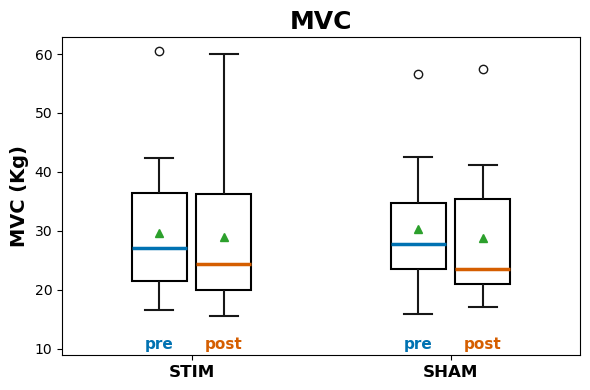

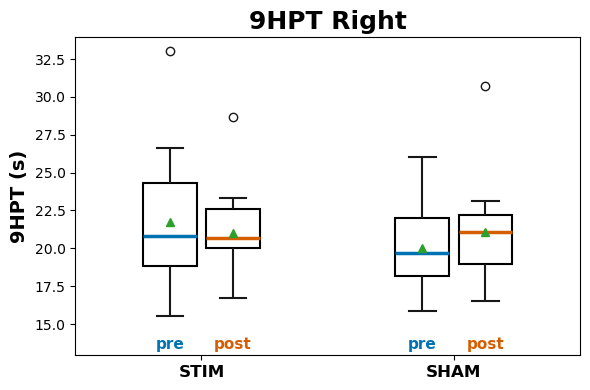

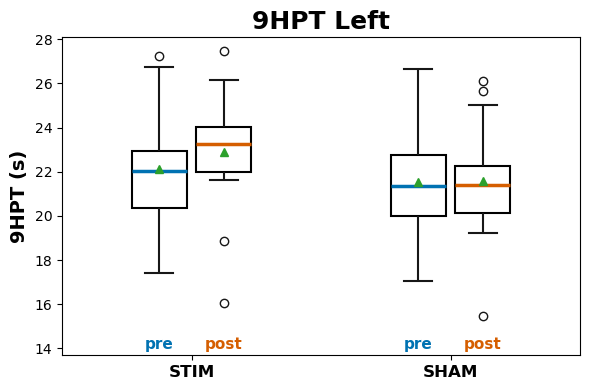


--- NORMALITY TEST ---
        Metric  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
           MVC        False          0.033         True          0.277
  9HPT_Derecha        False          0.034         True          0.218
9HPT_Izquierda         True          0.323         True          0.076

--- rmANOVA RESULTS ---
        Metric  Time (F, p)  Stim (F, p) Interaction (F, p)
           MVC 3.918, 0.069 0.079, 0.783       0.607, 0.450
  9HPT_Derecha 0.187, 0.672 3.280, 0.093       5.296, 0.039
9HPT_Izquierda 1.552, 0.235 5.348, 0.038       0.805, 0.386

--- POST-HOC (STIM CONDITION) ---
        Metric         Comparison  p-corr  Hedges g
           MVC POST vs PRE (STIM)   0.717    -0.048
  9HPT_Derecha POST vs PRE (STIM)   0.532    -0.182
9HPT_Izquierda POST vs PRE (STIM)   0.409     0.265


In [7]:
import pandas as pd
import pingouin as pg
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# ==============================================================================
# FUNCIÓN DE GRAFICADO (ESTÉTICA MINIMALISTA Y ORDENADA)
# ==============================================================================
def graficar_boxplot(df, metrica, titulo, ylabel):
    fig = plt.figure(figsize=(6, 4))
    
    ax = sns.boxplot(
        data=df, x='Stimulation', y=metrica, hue='Time',
        order=['STIM', 'SHAM'], hue_order=['PRE', 'POST'],
        color='white', width=0.5, gap=0.15, linewidth=1.5,
        showmeans=True,
        fliersize=6, medianprops=dict(linewidth=2.5)
    )
    
    for patch in ax.patches:
        patch.set_edgecolor('black')
        patch.set_facecolor('white')

    lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
    medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
    colores_estandar = ['#0072B2', '#D55E00', '#0072B2', '#D55E00']
    
    for mediana, color in zip(medianas_ordenadas, colores_estandar):
        mediana.set_color(color)

    plt.title(titulo, fontsize=18, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.xlabel('')
    plt.xticks(fontsize=12, fontweight='bold')
    
    if ax.legend_:
        ax.legend_.remove()
        
    y_min, y_max = df[metrica].min(), df[metrica].max()
    rango = y_max - y_min
    offset_y = rango * 0.08
    
    cajas = ax.patches[:4]
    cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
    posiciones_x = [p.get_path().get_extents().bounds[0] + (p.get_path().get_extents().bounds[2] / 2) for p in cajas_ordenadas]
    etiquetas = ['pre', 'post', 'pre', 'post']
    
    for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
        ax.text(x, y_min - offset_y, etiqueta, ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)
    
    plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
    plt.tight_layout()
    
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)
    fig.savefig(os.path.join(output_dir, f"{metrica}.png"), dpi=600, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# ==============================================================================
# ANÁLISIS ESTADÍSTICO UNIFICADO
# ==============================================================================
def run_statistical_pipeline(csv_filepath, config_metricas, usar_log=False, plot_validation=False):
    print("=" * 90)
    print(f"CARGANDO DATOS DESDE: {csv_filepath} | Bloque: Clínico (MVC & 9HPT)")
    print("=" * 90)
    
    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: Archivo '{csv_filepath}' no encontrado.")
        return
        
    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str)
    df['Time'] = df['Time'].astype(str)

    # Exclusión manual (Homologado: puedes dejar ['1', '2'] o ['1', '2', '10'])
    sujetos_excluidos_manual = ['1', '2', '10']
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]
    
    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == 4].index.tolist()
    df = df[df['Subject'].isin(sujetos_completos)].copy()
    
    print(f"Sujetos analizados con Cross-Over completo (N = {len(sujetos_completos)}): {sorted(sujetos_completos, key=int)}")
    
    df['Condicion_Cruzada'] = df['Stimulation'] + "_" + df['Time']
    tabla_normalidad, tabla_anova, tabla_posthoc = [], [], []
    
    for metrica, (titulo, ylabel) in config_metricas.items():
        if metrica not in df.columns:
            continue
            
        try:
            col_log = f"log_{metrica}"
            df[col_log] = np.log10(df[metrica])
            col_analisis = col_log if usar_log else metrica
            ylabel_plot = f"Log10 {ylabel}" if usar_log else ylabel
            
            # 1. Graficar Boxplot
            if plot_validation:
                graficar_boxplot(df, col_analisis, titulo, ylabel_plot)
            
            # 2. Pruebas de Normalidad por Condicion_Cruzada
            pvals_raw = pg.normality(data=df, dv=metrica, group='Condicion_Cruzada')['pval'].values
            pvals_log = pg.normality(data=df, dv=col_log, group='Condicion_Cruzada')['pval'].values
            
            tabla_normalidad.append({
                'Metric': metrica,
                'Raw Normal?': all(p > 0.05 for p in pvals_raw),
                'Raw Min p-val': round(min(pvals_raw), 3),
                'Log Normal?': all(p > 0.05 for p in pvals_log),
                'Log Min p-val': round(min(pvals_log), 3)
            })
            
            # 3. rmANOVA de 2 Vías
            anova = pg.rm_anova(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', detailed=True)
            ef_time = anova[anova['Source'] == 'Time']
            ef_stim = anova[anova['Source'] == 'Stimulation']
            ef_int = anova[anova['Source'] == 'Stimulation * Time']
            
            tabla_anova.append({
                'Metric': metrica,
                'Time (F, p)': f"{ef_time['F'].values[0]:.3f}, {ef_time['p-unc'].values[0]:.3f}",
                'Stim (F, p)': f"{ef_stim['F'].values[0]:.3f}, {ef_stim['p-unc'].values[0]:.3f}",
                'Interaction (F, p)': f"{ef_int['F'].values[0]:.3f}, {ef_int['p-unc'].values[0]:.3f}"
            })
            
            # 4. Post-Hoc (Bonferroni)
            ph = pg.pairwise_tests(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', padjust='bonf', parametric=True)
            ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]
            
            for _, row in ph_stim.iterrows():
                tabla_posthoc.append({
                    'Metric': metrica,
                    'Comparison': f"{row['A']} vs {row['B']} (STIM)",
                    'p-corr': round(row['p-corr'], 3),
                    'Hedges g': round(row['hedges'], 3)
                })
                
        except Exception as e:
            print(f"  [!] Error procesando {metrica}: {e}")

    print("\n--- NORMALITY TEST ---")
    print(pd.DataFrame(tabla_normalidad).to_string(index=False))
    print("\n--- rmANOVA RESULTS ---")
    print(pd.DataFrame(tabla_anova).to_string(index=False))
    print("\n--- POST-HOC (STIM CONDITION) ---")
    if tabla_posthoc:
        print(pd.DataFrame(tabla_posthoc).to_string(index=False))
    print("=" * 90)

if __name__ == '__main__':
    ARCHIVO_CSV = "Datos_Clinicos_MVC_9HTP.csv"
    configuracion_metricas = {
        'MVC': ('MVC', 'MVC (Kg)'),
        '9HPT_Derecha': ('9HPT Right', '9HPT (s)'),
        '9HPT_Izquierda': ('9HPT Left', '9HPT (s)')
    }

    generate_validation = True  # Cambiar a True si se desean las gráficas de validación

    run_statistical_pipeline(ARCHIVO_CSV, configuracion_metricas, usar_log=False, plot_validation=generate_validation)

## 1.2) Resting State EEG

In [15]:
import mne
import numpy as np
import pandas as pd
import os
import glob
import matplotlib.pyplot as plt

# ==============================================================================
# 0. Función de Generación de Gráficas de Validación (PSD Basal)
# ==============================================================================
def generate_validation_plots(epochs, subject_id, condition, time_blk, output_dir):
    """
    Genera gráficas de PSD (4 a 40 Hz) en C3 y C4 para validar visualmente 
    los bloques basales en reposo, sombreando las bandas Alfa y Beta.
    """
    fig_dir = os.path.join(output_dir, "Validation_Plots_Resting")
    os.makedirs(fig_dir, exist_ok=True)

    ch_plot = ['C3', 'C4']
    picks = [ch for ch in ch_plot if ch in epochs.ch_names]
    if not picks:
        return

    fig_psd, axes_psd = plt.subplots(1, len(picks), figsize=(6 * len(picks), 4.5))
    if len(picks) == 1:
        axes_psd = [axes_psd]

    psd_basal = epochs.compute_psd(method="multitaper", fmin=4, fmax=40, picks=picks, verbose=False)
    freqs = psd_basal.freqs

    for i, ch in enumerate(picks):
        ax = axes_psd[i]
        ax.plot(freqs, psd_basal.get_data(picks=ch).mean(axis=0)[0] * 1e12, label=f'Basal ({time_blk})', color='navy')
        ax.axvspan(8, 13, color='yellow', alpha=0.2, label='Alpha (8-13 Hz)')
        ax.axvspan(15, 29, color='pink', alpha=0.3, label='Beta (15-29 Hz)')

        ax.set_title(f"Resting PSD - {ch} ({condition} - {time_blk})", fontweight='bold')
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD (µV²/Hz)")
        ax.set_yscale('log')
        ax.grid(True)
        if i == 0:
            ax.legend()

    plt.tight_layout()
    fig_psd.savefig(os.path.join(fig_dir, f"RestingPSD_sub-{subject_id}_{condition}_{time_blk}.png"), dpi=300)
    plt.close(fig_psd)

# ==============================================================================
# 1. Función de Extracción Matemática (Potencia Beta por Archivo)
# ==============================================================================
def extract_metrics(epochs):
    """
    Extrae la potencia Beta estática (15 - 29 Hz) promediada a través de las épocas 
    y frecuencias para todos los canales, retornando un DataFrame de 1 fila.
    """
    canales = epochs.ch_names
    
    # Cálculo homogéneo con el bloque 2.3 (Multitaper 15-29 Hz, promediando épocas y frecuencias)
    psd_beta = epochs.compute_psd(method="multitaper", fmin=15, fmax=29, picks=canales, verbose=False).get_data().mean(axis=(0, 2))
    
    dict_beta = {ch: val for ch, val in zip(canales, psd_beta)}
    return pd.DataFrame([dict_beta])

# ==============================================================================
# 2. Pipeline Principal (Con Filtro de Sujetos)
# ==============================================================================
def process_metric(preprocessed_folder, output_csv, sujetos_a_procesar=None, plot_validation=False):
    print(f"Buscando archivos basales en: {preprocessed_folder}")
    
    search_pattern = os.path.join(preprocessed_folder, "*_blk-basal_*_eeg-epo.fif")
    archivos_basales = glob.glob(search_pattern)
    
    if not archivos_basales:
        print("No se encontraron archivos basales. Verifica la ruta.")
        return
        
    print(f"Se encontraron {len(archivos_basales)} archivos. Iniciando extracción...\n")
    lista_resultados = []
    base_out_dir = os.path.dirname(os.path.abspath(output_csv)) or os.getcwd()
    
    for filepath in archivos_basales:
        filename = os.path.basename(filepath)
        
        try:
            partes = filename.split('_')
            subject_id = partes[0].split('-')[1]
            
            if sujetos_a_procesar is not None and subject_id not in sujetos_a_procesar:
                continue
                
            condition = partes[1].split('-')[1].upper()
            
            if 'pre' in filename.lower(): time_blk = 'PRE'
            elif 'post' in filename.lower(): time_blk = 'POST'
            else: continue
                
            print(f"Procesando: Sujeto {subject_id} | {condition} | {time_blk}")
            
            epochs = mne.read_epochs(filepath, preload=True, verbose=False)
            
            if plot_validation:
                generate_validation_plots(epochs, subject_id, condition, time_blk, base_out_dir)
            
            df_resumen = extract_metrics(epochs)
            df_resumen['Subject'] = subject_id
            df_resumen['Stimulation'] = condition
            df_resumen['Time'] = time_blk
            
            lista_resultados.append(df_resumen)
            
        except Exception as e:
            print(f"  [!] Error procesando {filename}: {e}")
            
    print("\nConsolidando tabla maestra...")
    if lista_resultados:
        df_maestro = pd.concat(lista_resultados, ignore_index=True)
        cols_metadatos = ['Subject', 'Stimulation', 'Time']
        cols_canales = [c for c in df_maestro.columns if c not in cols_metadatos]
        df_maestro = df_maestro[cols_metadatos + cols_canales]
        
        df_maestro.to_csv(output_csv, index=False)
        print(f"\n¡Éxito! Matriz estadística exportada a: {output_csv}")
        print(df_maestro.head())

# ==============================================================================
# EJECUCIÓN
# ==============================================================================
if __name__ == '__main__':
    Preprocessed_Data_Folder = r"E:\Yoyi\Preprocessed Data"
    Archivo_Salida_CSV = "Beta_Power_RM_ANOVA.csv"

    generate_validation = True  # Cambiar a True si se desean las gráficas de validación
    
    process_metric(Preprocessed_Data_Folder, Archivo_Salida_CSV, plot_validation=generate_validation)

Buscando archivos basales en: E:\Yoyi\Preprocessed Data
Se encontraron 68 archivos. Iniciando extracción...

Procesando: Sujeto 10 | SHAM | POST
Procesando: Sujeto 10 | SHAM | PRE
Procesando: Sujeto 10 | STIM | POST
Procesando: Sujeto 10 | STIM | PRE
Procesando: Sujeto 11 | SHAM | POST
Procesando: Sujeto 11 | SHAM | PRE
Procesando: Sujeto 11 | STIM | POST
Procesando: Sujeto 11 | STIM | PRE
Procesando: Sujeto 12 | SHAM | POST
Procesando: Sujeto 12 | SHAM | PRE
Procesando: Sujeto 12 | STIM | POST
Procesando: Sujeto 12 | STIM | PRE
Procesando: Sujeto 13 | SHAM | POST
Procesando: Sujeto 13 | SHAM | PRE
Procesando: Sujeto 13 | STIM | POST
Procesando: Sujeto 13 | STIM | PRE
Procesando: Sujeto 14 | SHAM | POST
Procesando: Sujeto 14 | SHAM | PRE
Procesando: Sujeto 15 | STIM | POST
Procesando: Sujeto 15 | STIM | PRE
Procesando: Sujeto 16 | SHAM | POST
Procesando: Sujeto 16 | SHAM | PRE
Procesando: Sujeto 16 | STIM | POST
Procesando: Sujeto 16 | STIM | PRE
Procesando: Sujeto 17 | SHAM | POST
Pro

### Statistical Analysis

CARGANDO DATOS DESDE: Beta_Power_RM_ANOVA.csv | Bloque: Resting State EEG
Sujetos analizados con Cross-Over completo (N = 14): ['5', '6', '7', '8', '9', '11', '12', '13', '16', '17', '18', '19', '20', '21']


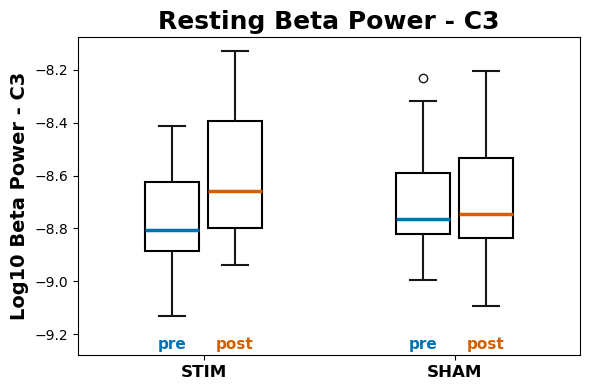

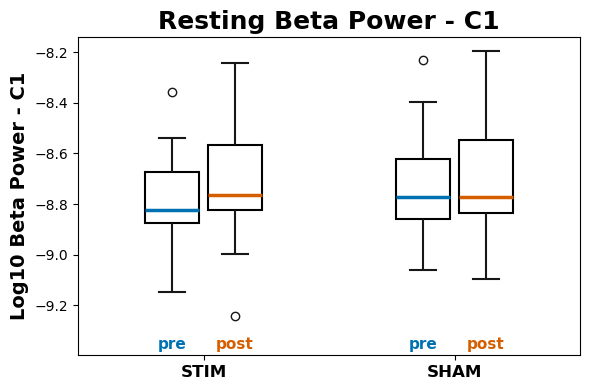

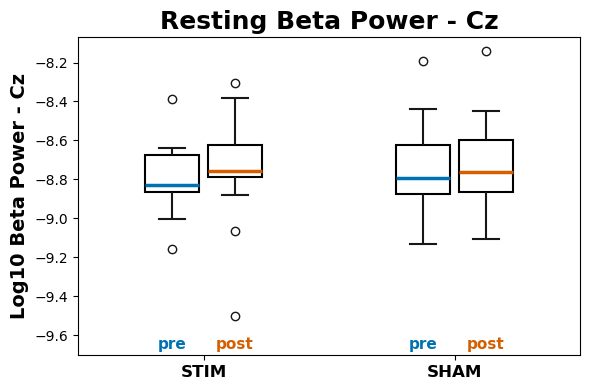

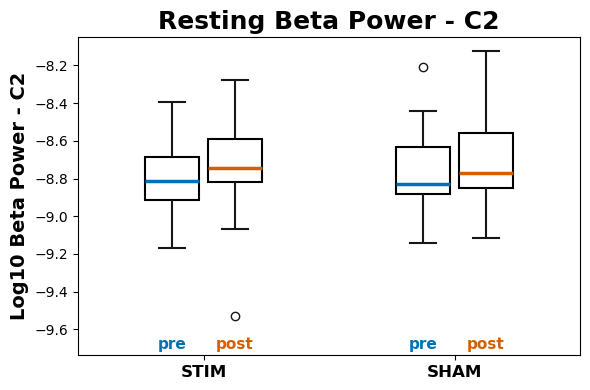

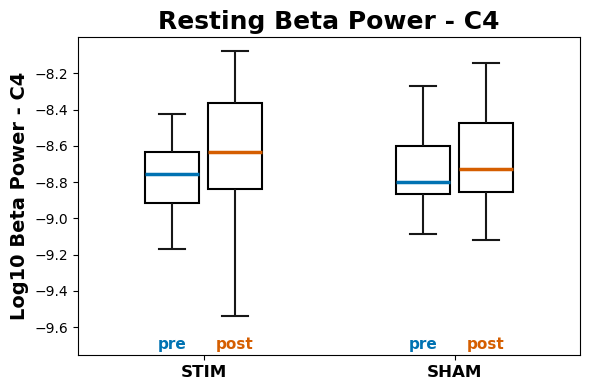

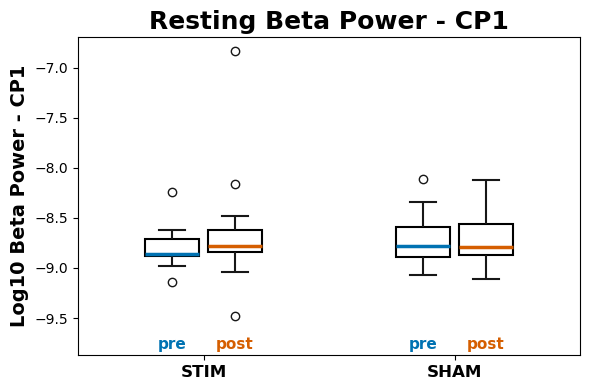

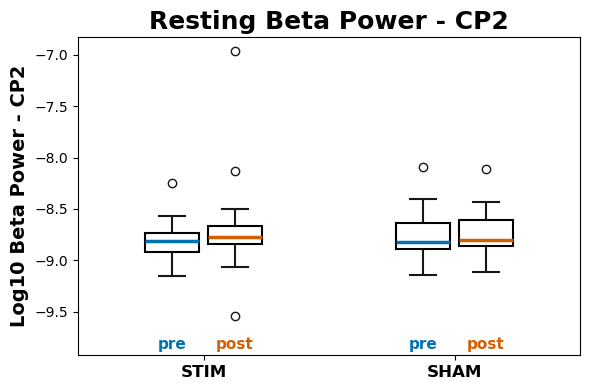

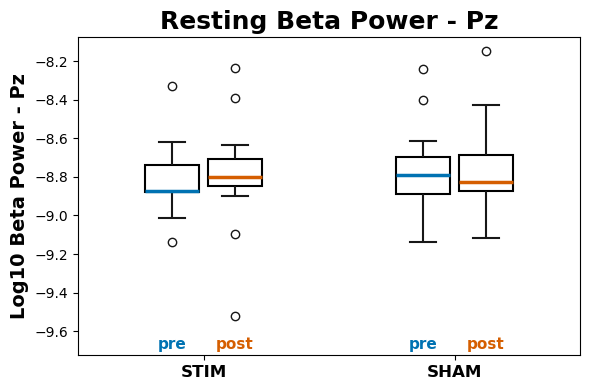


--- NORMALITY TEST ---
Channel  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
     C3        False          0.005         True          0.349
     C1        False          0.004         True          0.519
     Cz        False          0.001         True          0.109
     C2        False          0.001         True          0.173
     C4        False          0.015         True          0.597
    CP1        False          0.000        False          0.001
    CP2        False          0.000        False          0.002
     Pz        False          0.000         True          0.108

--- rmANOVA RESULTS ---
Channel  Time (F, p)  Stim (F, p) Interaction (F, p)
     C3 7.076, 0.020 0.186, 0.673       4.391, 0.056
     C1 3.672, 0.078 1.712, 0.213       4.831, 0.047
     Cz 1.540, 0.237 2.299, 0.153       1.701, 0.215
     C2 2.366, 0.148 1.098, 0.314       1.524, 0.239
     C4 3.060, 0.104 0.001, 0.977       2.187, 0.163
    CP1 1.317, 0.272 0.000, 0.990       1.534, 0.237
    

In [3]:
import pandas as pd
import pingouin as pg
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# ==============================================================================
# FUNCIÓN DE GRAFICADO (2 NIVELES TEMPORALES: PRE vs POST)
# ==============================================================================
def graficar_boxplot(df, metrica, titulo, ylabel):
    fig = plt.figure(figsize=(6, 4))
    
    ax = sns.boxplot(
        data=df, x='Stimulation', y=metrica, hue='Time',
        order=['STIM', 'SHAM'], hue_order=['PRE', 'POST'],
        color='white', width=0.5, gap=0.15, linewidth=1.5,
        fliersize=6, medianprops=dict(linewidth=2.5)
    )
    
    for patch in ax.patches:
        patch.set_edgecolor('black')
        patch.set_facecolor('white')

    lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
    medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
    colores_estandar = ['#0072B2', '#D55E00', '#0072B2', '#D55E00']
    
    for mediana, color in zip(medianas_ordenadas, colores_estandar):
        mediana.set_color(color)

    plt.title(titulo, fontsize=18, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.xlabel('')
    plt.xticks(fontsize=12, fontweight='bold')
    
    if ax.legend_:
        ax.legend_.remove()
        
    y_min, y_max = df[metrica].min(), df[metrica].max()
    rango = y_max - y_min
    offset_y = rango * 0.08
    
    cajas = ax.patches[:4]
    cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
    posiciones_x = [p.get_path().get_extents().bounds[0] + (p.get_path().get_extents().bounds[2] / 2) for p in cajas_ordenadas]
    etiquetas = ['pre', 'post', 'pre', 'post']
    
    for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
        ax.text(x, y_min - offset_y, etiqueta, ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)
    
    plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
    plt.tight_layout()
    
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)
    fig.savefig(os.path.join(output_dir, f"Resting_{metrica}.png"), dpi=600, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# ==============================================================================
# ANÁLISIS ESTADÍSTICO UNIFICADO
# ==============================================================================
def run_statistical_pipeline(csv_filepath, canales, plot_validation=False):
    print("=" * 90)
    print(f"CARGANDO DATOS DESDE: {csv_filepath} | Bloque: Resting State EEG")
    print("=" * 90)
    
    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: Archivo '{csv_filepath}' no encontrado.")
        return
        
    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str)
    df['Time'] = df['Time'].astype(str)
    
    sujetos_excluidos_manual = ['1', '2', '10']
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]

    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == 4].index.tolist()
    df = df[df['Subject'].isin(sujetos_completos)].copy()
    
    print(f"Sujetos analizados con Cross-Over completo (N = {len(sujetos_completos)}): {sorted(sujetos_completos, key=int)}")
    
    df['Condicion_Cruzada'] = df['Stimulation'] + "_" + df['Time']
    tabla_normalidad, tabla_anova, tabla_posthoc = [], [], []
    
    for canal in canales:
        if canal not in df.columns:
            continue
            
        try:
            # 1. Transformar a Log10 ANTES de graficar (homologado con 2.3)
            col_analisis = f"log_{canal}"
            df[col_analisis] = np.log10(df[canal])
            
            # 2. Generar Boxplot sobre los datos transformados
            if plot_validation:
                graficar_boxplot(df, col_analisis, f"Resting Beta Power - {canal}", f"Log10 Beta Power - {canal}")
            
            # 3. Pruebas de Normalidad
            pvals_raw = pg.normality(data=df, dv=canal, group='Condicion_Cruzada')['pval'].values
            pvals_log = pg.normality(data=df, dv=col_analisis, group='Condicion_Cruzada')['pval'].values
            
            tabla_normalidad.append({
                'Channel': canal,
                'Raw Normal?': all(p > 0.05 for p in pvals_raw),
                'Raw Min p-val': round(min(pvals_raw), 3),
                'Log Normal?': all(p > 0.05 for p in pvals_log),
                'Log Min p-val': round(min(pvals_log), 3)
            })
            
            # 4. rmANOVA
            anova = pg.rm_anova(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', detailed=True)
            ef_time = anova[anova['Source'] == 'Time']
            ef_stim = anova[anova['Source'] == 'Stimulation']
            ef_int = anova[anova['Source'] == 'Stimulation * Time']
            
            tabla_anova.append({
                'Channel': canal,
                'Time (F, p)': f"{ef_time['F'].values[0]:.3f}, {ef_time['p-unc'].values[0]:.3f}",
                'Stim (F, p)': f"{ef_stim['F'].values[0]:.3f}, {ef_stim['p-unc'].values[0]:.3f}",
                'Interaction (F, p)': f"{ef_int['F'].values[0]:.3f}, {ef_int['p-unc'].values[0]:.3f}"
            })
            
            # 5. Post-Hoc
            ph = pg.pairwise_tests(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', padjust='bonf', parametric=True)
            ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]
            
            for _, row in ph_stim.iterrows():
                tabla_posthoc.append({
                    'Channel': canal,
                    'Comparison': f"{row['A']} vs {row['B']} (STIM)",
                    'p-corr': round(row['p-corr'], 3),
                    'Hedges g': round(row['hedges'], 3)
                })
                
        except Exception as e:
            print(f"  [!] Error procesando el canal {canal}: {e}")

    print("\n--- NORMALITY TEST ---")
    print(pd.DataFrame(tabla_normalidad).to_string(index=False))
    print("\n--- rmANOVA RESULTS ---")
    print(pd.DataFrame(tabla_anova).to_string(index=False))
    print("\n--- POST-HOC (STIM CONDITION) ---")
    if tabla_posthoc:
        print(pd.DataFrame(tabla_posthoc).to_string(index=False))
    print("=" * 90)

if __name__ == '__main__':
    ARCHIVO_CSV = "Beta_Power_RM_ANOVA.csv"
    canales_eeg = ['C3', 'C1', 'Cz', 'C2', 'C4', 'CP1', 'CP2', 'Pz']

    generate_validation = True  # Cambiar a True si se desean las gráficas de validación

    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, plot_validation=generate_validation)

# 2) Intervention Block Analysis

## 2.1) Kinematic

In [17]:
import mne
import numpy as np
import pandas as pd
import os
import glob
import math
import matplotlib.pyplot as plt

# Coordenadas ideales y diccionario de eventos CORREGIDO (1: Flexion, 2: Extension)
EndPoints = {
    ("Flexion", "FORWARD"): (-80, 0), ("Flexion", "BACKWARD"): (0, 0),
    ("Extension", "FORWARD"): (80, 0), ("Extension", "BACKWARD"): (0, 0),
    ("Radial D.", "FORWARD"): (0, 70), ("Radial D.", "BACKWARD"): (0, 0),
    ("Ulnar D.", "FORWARD"): (0, -70), ("Ulnar D.", "BACKWARD"): (0, 0),
    ("D1", "FORWARD"): (-57, 50), ("D1", "BACKWARD"): (0, 0),
    ("D2", "FORWARD"): (57, 50), ("D2", "BACKWARD"): (0, 0),
    ("D3", "FORWARD"): (57, -50), ("D3", "BACKWARD"): (0, 0),
    ("D4", "FORWARD"): (-57, -50), ("D4", "BACKWARD"): (0, 0)
}

TargetIDs = {1: "Flexion", 2: "Extension", 3: "Radial D.", 4: "Ulnar D.", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}
FS = 2400

def ComputeAccuracy(movement, RawData, movementDirection):
    Xf, Yf = EndPoints[(movement, movementDirection)]
    idx = int(3/4 * np.shape(RawData)[1]) - 1 if movementDirection == "FORWARD" else np.shape(RawData)[1] - 1
    Xi, Yi = RawData[0, idx], RawData[1, idx]
    return math.sqrt((Xi - Xf)**2 + (Yi - Yf)**2)

def ComputeExcecutionTime(movement, RawData, movementDirection):
    Xf, Yf = EndPoints[(movement, movementDirection)]
    if movementDirection == "FORWARD":
        indexI, indexF, timeOffset = int(1/2 * np.shape(RawData)[1]) - 1, int(3/4 * np.shape(RawData)[1]) - 1, 5.0
    else:
        indexI, indexF, timeOffset = int(3/4 * np.shape(RawData)[1]) - 1, np.shape(RawData)[1] - 1, 7.5

    targetHit = False
    for i in range(indexI, indexF):
        distance = math.sqrt((RawData[0, i] - Xf)**2 + (RawData[1, i] - Yf)**2)
        if distance <= 8:
            if not targetHit:
                ExcecutionTime = (i / FS) - timeOffset
                targetHit = True
        else:
            targetHit = False
    return ExcecutionTime if targetHit else np.nan

def ComputeTrayectoryEfficiency(movement, RawData, movementDirection):
    if movementDirection == "FORWARD":
        Current_Trayectory = RawData[:, int(1/2 * np.shape(RawData)[1]):int(3/4 * np.shape(RawData)[1])]
    else:
        Current_Trayectory = RawData[:, int(3/4 * np.shape(RawData)[1]):np.shape(RawData)[1]]

    IdealTrayectoryDistance = math.sqrt(
        (Current_Trayectory[0, -1] - Current_Trayectory[0, 0])**2 +
        (Current_Trayectory[1, -1] - Current_Trayectory[1, 0])**2
    )
    if IdealTrayectoryDistance == 0:
        return np.nan

    diffs = np.diff(Current_Trayectory[:2, :], axis=1)
    PartialDistanceTraveled = np.sum(np.sqrt(np.sum(diffs**2, axis=0)))
    return PartialDistanceTraveled / IdealTrayectoryDistance

def CheckStarAndEndPoints(movement, RawData, movementDirection):
    XfIdeal, YfIdeal = EndPoints[(movement, movementDirection)]
    if movementDirection == "FORWARD":
        Xi, Yi = RawData[0, int(1/2 * np.shape(RawData)[1])], RawData[1, int(1/2 * np.shape(RawData)[1])]
        Xf, Yf = RawData[0, int(3/4 * np.shape(RawData)[1]) - 1], RawData[1, int(3/4 * np.shape(RawData)[1]) - 1]
        XiIdeal, YiIdeal = EndPoints[(movement, "BACKWARD")]
    else:
        Xi, Yi = RawData[0, int(3/4 * np.shape(RawData)[1])], RawData[1, int(3/4 * np.shape(RawData)[1])]
        Xf, Yf = RawData[0, -1], RawData[1, -1]
        XiIdeal, YiIdeal = EndPoints[(movement, "FORWARD")]

    Initial_Displacement = math.sqrt((Xi - XiIdeal)**2 + (Yi - YiIdeal)**2)
    Final_Displacement = math.sqrt((Xf - XfIdeal)**2 + (Yf - YfIdeal)**2)
    return 1 if (Initial_Displacement < 8 and Final_Displacement < 8) else 0

# ==============================================================================
# 0. Función de Generación de Gráficas de Validación (Trayectorias 2D)
# ==============================================================================
def generate_validation_plots(epochs, subject_id, condition, time_blk, output_dir, run_name=""):
    """
    Grafica las trayectorias 2D (X vs Y) de todos los ensayos del archivo para 
    validar visualmente el desempeño espacial hacia las 8 metas.
    """
    fig_dir = os.path.join(output_dir, "Validation_Plots_Kinematics")
    os.makedirs(fig_dir, exist_ok=True)
    
    datos = epochs.get_data()
    n_pts = datos.shape[2]
    idx_start_fwd = int(0.5 * n_pts)
    idx_end_fwd = int(0.75 * n_pts)
    
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
    
    for trial in datos:
        axs[0].plot(trial[0, idx_start_fwd:idx_end_fwd], trial[1, idx_start_fwd:idx_end_fwd], alpha=0.35, lw=1)
        axs[1].plot(trial[0, idx_end_fwd:], trial[1, idx_end_fwd:], alpha=0.35, lw=1)
        
    for ax, direccion in zip(axs, ["FORWARD", "BACKWARD"]):
        for mov, dir_key in EndPoints.keys():
            if dir_key == "FORWARD":
                tx, ty = EndPoints[(mov, "FORWARD")]
                ax.scatter(tx, ty, c='red', s=40, zorder=5)
        ax.scatter(0, 0, c='black', s=50, zorder=5)
        ax.set_title(f"{direccion} ({condition} - {time_blk})", fontweight='bold')
        ax.set_xlabel("X Position")
        ax.set_ylabel("Y Position")
        ax.set_xlim(-100, 100)
        ax.set_ylim(-100, 100)
        ax.grid(True, alpha=0.3)
        
    plt.tight_layout()
    tag = run_name.replace('.fif', '') if run_name else f"sub-{subject_id}_{condition}_{time_blk}"
    fig.savefig(os.path.join(fig_dir, f"Kin_{tag}.png"), dpi=300)
    plt.close(fig)

# ==============================================================================
# 1. Función de Extracción Matemática por Archivo (1 RUN)
# ==============================================================================
def extract_metrics(epochs):
    """
    Extrae las métricas cinemáticas de las fases FORWARD y BACKWARD para cada trial
    y retorna el promedio del run en un DataFrame de 1 fila.
    """
    events = epochs.events[:, 2]
    datos_cinematicos = epochs.get_data()
    lista_metricas_trials = []
    
    for trial_idx, trial_data in enumerate(datos_cinematicos):
        mov_name = TargetIDs[events[trial_idx]]
        
        # --- FORWARD ---
        valid_fwd = CheckStarAndEndPoints(mov_name, trial_data, "FORWARD")
        if valid_fwd:
            prec_fwd = ComputeAccuracy(mov_name, trial_data, "FORWARD")
            time_fwd = ComputeExcecutionTime(mov_name, trial_data, "FORWARD")
            eff_fwd  = ComputeTrayectoryEfficiency(mov_name, trial_data, "FORWARD")
        else:
            prec_fwd = time_fwd = eff_fwd = np.nan
            
        # --- BACKWARD ---
        valid_bwd = CheckStarAndEndPoints(mov_name, trial_data, "BACKWARD")
        if valid_bwd:
            prec_bwd = ComputeAccuracy(mov_name, trial_data, "BACKWARD")
            time_bwd = ComputeExcecutionTime(mov_name, trial_data, "BACKWARD")
            eff_bwd  = ComputeTrayectoryEfficiency(mov_name, trial_data, "BACKWARD")
        else:
            prec_bwd = time_bwd = eff_bwd = np.nan

        lista_metricas_trials.append({
            'Fwd_Valid': valid_fwd, 'Fwd_Precision': prec_fwd,
            'Fwd_ExecTime': time_fwd, 'Fwd_Efficiency': eff_fwd,
            'Bwd_Valid': valid_bwd, 'Bwd_Precision': prec_bwd,
            'Bwd_ExecTime': time_bwd, 'Bwd_Efficiency': eff_bwd
        })
        
    df_trials = pd.DataFrame(lista_metricas_trials)
    return df_trials.mean(numeric_only=True).to_frame().T

# ==============================================================================
# 2. Pipeline Principal (Con Filtro de Sujetos)
# ==============================================================================
def process_metric(preprocessed_folder, output_csv, sujetos_a_procesar=None, plot_validation=False):
    print(f"Buscando archivos cinemáticos en: {preprocessed_folder}")
    
    todos_archivos = glob.glob(os.path.join(preprocessed_folder, "*_kin-epo.fif"))
    archivos_kin = [
        f for f in todos_archivos 
        if ("blk-pre" in os.path.basename(f).lower() or "blk-post" in os.path.basename(f).lower())
    ]
    
    if not archivos_kin:
        print("No se encontraron archivos de cinemática válidos (PRE o POST). Verifica la ruta.")
        return
        
    print(f"Se filtraron {len(archivos_kin)} archivos de tarea motora. Iniciando extracción...\n")
    lista_resultados_runs = []
    base_out_dir = os.path.dirname(os.path.abspath(output_csv)) or os.getcwd()
    
    for filepath in archivos_kin:
        filename = os.path.basename(filepath)
        
        try:
            partes = filename.split('_')
            subject_id = partes[0].split('-')[1]
            
            if sujetos_a_procesar is not None and subject_id not in sujetos_a_procesar:
                continue
                
            condition = partes[1].split('-')[1].upper()
            
            if 'pre' in filename.lower(): time_blk = 'PRE'
            elif 'post' in filename.lower(): time_blk = 'POST'
            else: continue
                
            print(f"Procesando: Sujeto {subject_id} | {condition} | {time_blk} | Archivo: {filename}")
            
            epochs = mne.read_epochs(filepath, preload=True, verbose=False)
            
            if plot_validation:
                generate_validation_plots(epochs, subject_id, condition, time_blk, base_out_dir, run_name=filename)
                
            df_resumen_run = extract_metrics(epochs)
            df_resumen_run['Subject'] = subject_id
            df_resumen_run['Stimulation'] = condition
            df_resumen_run['Time'] = time_blk
            
            lista_resultados_runs.append(df_resumen_run)
            
        except Exception as e:
            print(f"  [!] Error procesando {filename}: {e}")

    print("\nConsolidando tabla maestra y promediando por Sujeto, Estimulación y Fase...")
    if lista_resultados_runs:
        df_todos_runs = pd.concat(lista_resultados_runs, ignore_index=True)
        df_maestro = df_todos_runs.groupby(['Subject', 'Stimulation', 'Time']).mean(numeric_only=True).reset_index()
        
        cols_metadatos = ['Subject', 'Stimulation', 'Time']
        cols_metricas = [c for c in df_maestro.columns if c not in cols_metadatos]
        df_maestro = df_maestro[cols_metadatos + cols_metricas]
        
        df_maestro.to_csv(output_csv, index=False)
        print(f"\n¡Éxito! Matriz cinemática PROMEDIADA exportada a: {output_csv}")
        print(df_maestro.head())

if __name__ == '__main__':
    Preprocessed_Data_Folder = r"E:\Yoyi\Preprocessed Data"
    Archivo_Salida_CSV = "Kinematics_RM_ANOVA.csv"

    generate_validation = True  # Cambiar a True si se desean las gráficas de validación
    
    process_metric(Preprocessed_Data_Folder, Archivo_Salida_CSV, plot_validation=generate_validation)

Buscando archivos cinemáticos en: E:\Yoyi\Preprocessed Data
Se filtraron 68 archivos de tarea motora. Iniciando extracción...

Procesando: Sujeto 10 | SHAM | POST | Archivo: sub-10_cond-sham_blk-post_kin-epo.fif
Procesando: Sujeto 10 | SHAM | PRE | Archivo: sub-10_cond-sham_blk-pre_kin-epo.fif
Procesando: Sujeto 10 | STIM | POST | Archivo: sub-10_cond-stim_blk-post_kin-epo.fif
Procesando: Sujeto 10 | STIM | PRE | Archivo: sub-10_cond-stim_blk-pre_kin-epo.fif
Procesando: Sujeto 11 | SHAM | POST | Archivo: sub-11_cond-sham_blk-post_kin-epo.fif
Procesando: Sujeto 11 | SHAM | PRE | Archivo: sub-11_cond-sham_blk-pre_kin-epo.fif
Procesando: Sujeto 11 | STIM | POST | Archivo: sub-11_cond-stim_blk-post_kin-epo.fif
Procesando: Sujeto 11 | STIM | PRE | Archivo: sub-11_cond-stim_blk-pre_kin-epo.fif
Procesando: Sujeto 12 | SHAM | POST | Archivo: sub-12_cond-sham_blk-post_kin-epo.fif
Procesando: Sujeto 12 | SHAM | PRE | Archivo: sub-12_cond-sham_blk-pre_kin-epo.fif
Procesando: Sujeto 12 | STIM | PO

### Statistical Analysis

CARGANDO DATOS DESDE: Kinematics_RM_ANOVA.csv | Bloque: Kinematics
Sujetos analizados con Cross-Over completo (N = 14): ['5', '6', '7', '8', '9', '11', '12', '13', '16', '17', '18', '19', '20', '21']


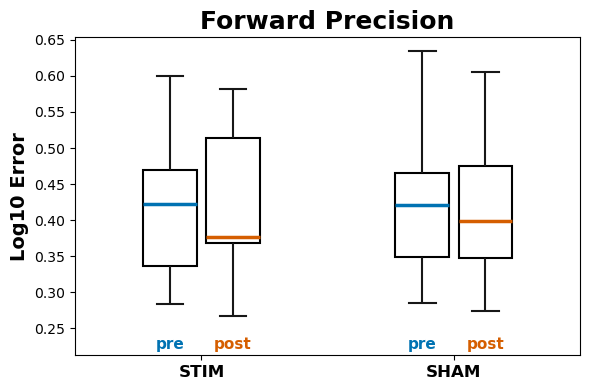

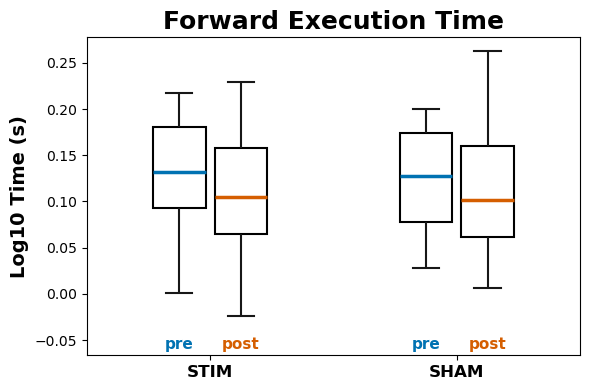

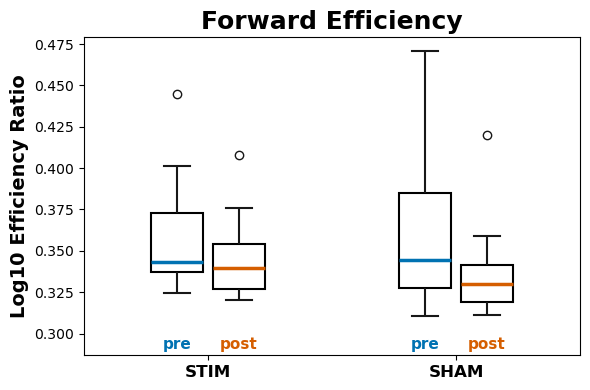

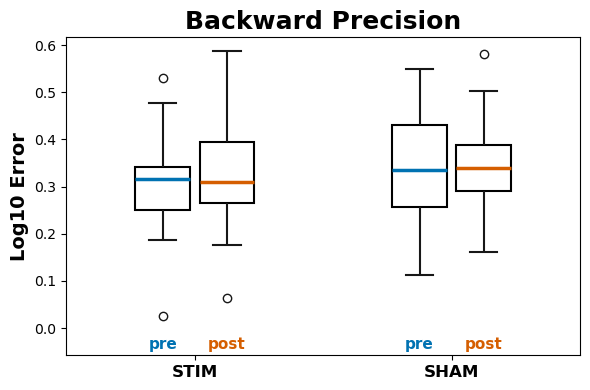

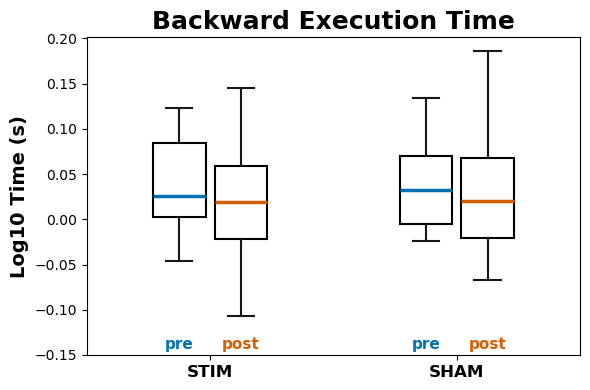

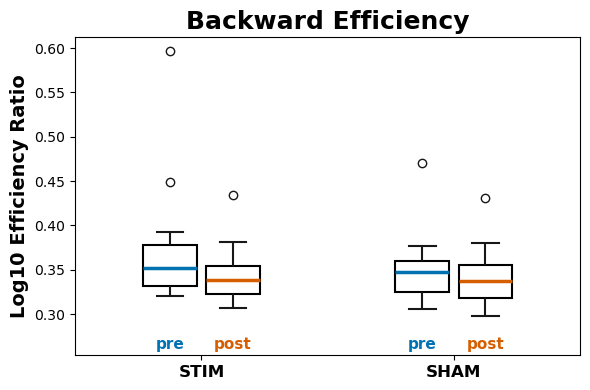


--- NORMALITY TEST ---
        Metric  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
 Fwd_Precision         True          0.067         True          0.149
  Fwd_ExecTime         True          0.302         True          0.483
Fwd_Efficiency        False          0.001        False          0.002
 Bwd_Precision         True          0.110         True          0.468
  Bwd_ExecTime         True          0.160         True          0.226
Bwd_Efficiency        False          0.000        False          0.000

--- rmANOVA RESULTS ---
        Metric   Time (F, p)  Stim (F, p) Interaction (F, p)
 Fwd_Precision  0.329, 0.576 0.004, 0.952       0.018, 0.896
  Fwd_ExecTime  6.115, 0.028 0.135, 0.719       1.364, 0.264
Fwd_Efficiency 12.384, 0.004 0.008, 0.929       1.469, 0.247
 Bwd_Precision  0.546, 0.473 1.839, 0.198       0.011, 0.919
  Bwd_ExecTime  3.248, 0.095 0.235, 0.636       0.337, 0.571
Bwd_Efficiency  6.577, 0.024 1.901, 0.191       1.215, 0.290

--- POST-HOC (STIM CONDITI

In [18]:
import pandas as pd
import pingouin as pg
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# ==============================================================================
# FUNCIÓN DE GRAFICADO (2 NIVELES TEMPORALES: PRE vs POST)
# ==============================================================================
def graficar_boxplot(df, metrica, titulo, ylabel):
    fig = plt.figure(figsize=(6, 4))
    
    ax = sns.boxplot(
        data=df, x='Stimulation', y=metrica, hue='Time',
        order=['STIM', 'SHAM'], hue_order=['PRE', 'POST'],
        color='white', width=0.5, gap=0.15, linewidth=1.5,
        fliersize=6, medianprops=dict(linewidth=2.5)
    )
    
    for patch in ax.patches:
        patch.set_edgecolor('black')
        patch.set_facecolor('white')

    lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
    medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
    colores_estandar = ['#0072B2', '#D55E00', '#0072B2', '#D55E00']
    
    for mediana, color in zip(medianas_ordenadas, colores_estandar):
        mediana.set_color(color)

    plt.title(titulo, fontsize=18, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.xlabel('')
    plt.xticks(fontsize=12, fontweight='bold')
    
    if ax.legend_:
        ax.legend_.remove()
        
    y_min, y_max = df[metrica].min(), df[metrica].max()
    rango = y_max - y_min
    offset_y = rango * 0.08
    
    cajas = ax.patches[:4]
    cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
    posiciones_x = [p.get_path().get_extents().bounds[0] + (p.get_path().get_extents().bounds[2] / 2) for p in cajas_ordenadas]
    etiquetas = ['pre', 'post', 'pre', 'post']
    
    for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
        ax.text(x, y_min - offset_y, etiqueta, ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)
    
    plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
    plt.tight_layout()
    
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)
    fig.savefig(os.path.join(output_dir, f"{metrica}.png"), dpi=600, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# ==============================================================================
# ANÁLISIS ESTADÍSTICO UNIFICADO
# ==============================================================================
def run_statistical_pipeline(csv_filepath, config_metricas, usar_log=True, plot_validation=False):
    print("=" * 90)
    print(f"CARGANDO DATOS DESDE: {csv_filepath} | Bloque: Kinematics")
    print("=" * 90)
    
    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: Archivo '{csv_filepath}' no encontrado.")
        return
        
    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str)
    df['Time'] = df['Time'].astype(str)
    
    sujetos_excluidos_manual = ['1', '2', '10']
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]
    
    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == 4].index.tolist()
    df = df[df['Subject'].isin(sujetos_completos)].copy()
    
    print(f"Sujetos analizados con Cross-Over completo (N = {len(sujetos_completos)}): {sorted(sujetos_completos, key=int)}")
    
    df['Condicion_Cruzada'] = df['Stimulation'] + "_" + df['Time']
    tabla_normalidad, tabla_anova, tabla_posthoc = [], [], []
    
    for metrica, (titulo, ylabel) in config_metricas.items():
        if metrica not in df.columns:
            continue
            
        try:
            col_log = f"log_{metrica}"
            df[col_log] = np.log10(df[metrica])
            col_analisis = col_log if usar_log else metrica
            ylabel_plot = f"Log10 {ylabel}" if usar_log else ylabel
            
            # 1. Graficar Boxplot
            if plot_validation:
                graficar_boxplot(df, col_analisis, titulo, ylabel_plot)
            
            # 2. Pruebas de Normalidad
            pvals_raw = pg.normality(data=df, dv=metrica, group='Condicion_Cruzada')['pval'].values
            pvals_log = pg.normality(data=df, dv=col_log, group='Condicion_Cruzada')['pval'].values
            
            tabla_normalidad.append({
                'Metric': metrica,
                'Raw Normal?': all(p > 0.05 for p in pvals_raw),
                'Raw Min p-val': round(min(pvals_raw), 3),
                'Log Normal?': all(p > 0.05 for p in pvals_log),
                'Log Min p-val': round(min(pvals_log), 3)
            })
            
            # 3. rmANOVA
            anova = pg.rm_anova(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', detailed=True)
            ef_time = anova[anova['Source'] == 'Time']
            ef_stim = anova[anova['Source'] == 'Stimulation']
            ef_int = anova[anova['Source'] == 'Stimulation * Time']
            
            tabla_anova.append({
                'Metric': metrica,
                'Time (F, p)': f"{ef_time['F'].values[0]:.3f}, {ef_time['p-unc'].values[0]:.3f}",
                'Stim (F, p)': f"{ef_stim['F'].values[0]:.3f}, {ef_stim['p-unc'].values[0]:.3f}",
                'Interaction (F, p)': f"{ef_int['F'].values[0]:.3f}, {ef_int['p-unc'].values[0]:.3f}"
            })
            
            # 4. Post-Hoc
            ph = pg.pairwise_tests(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', padjust='bonf', parametric=True)
            ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]
            
            for _, row in ph_stim.iterrows():
                tabla_posthoc.append({
                    'Metric': metrica,
                    'Comparison': f"{row['A']} vs {row['B']} (STIM)",
                    'p-corr': round(row['p-corr'], 3),
                    'Hedges g': round(row['hedges'], 3)
                })
                
        except Exception as e:
            print(f"  [!] Error procesando {metrica}: {e}")

    print("\n--- NORMALITY TEST ---")
    print(pd.DataFrame(tabla_normalidad).to_string(index=False))
    print("\n--- rmANOVA RESULTS ---")
    print(pd.DataFrame(tabla_anova).to_string(index=False))
    print("\n--- POST-HOC (STIM CONDITION) ---")
    if tabla_posthoc:
        print(pd.DataFrame(tabla_posthoc).to_string(index=False))
    print("=" * 90)

if __name__ == '__main__':
    ARCHIVO_CSV = "Kinematics_RM_ANOVA.csv"
    configuracion_metricas = {
        'Fwd_Precision': ('Forward Precision', 'Error'),
        'Fwd_ExecTime': ('Forward Execution Time', 'Time (s)'),
        'Fwd_Efficiency': ('Forward Efficiency', 'Efficiency Ratio'),
        'Bwd_Precision': ('Backward Precision', 'Error'),
        'Bwd_ExecTime': ('Backward Execution Time', 'Time (s)'),
        'Bwd_Efficiency': ('Backward Efficiency', 'Efficiency Ratio')
    }

    generate_validation = True  # Cambiar a True si se desean las gráficas de validación

    run_statistical_pipeline(ARCHIVO_CSV, configuracion_metricas, usar_log=True, plot_validation=generate_validation)

## 2.2) PSD & ERD/ERS

In [19]:
import mne
import numpy as np
import pandas as pd
import os
import glob
import gc
import matplotlib.pyplot as plt
import scipy.stats as stats

# ==============================================================================
# 0. Función de Generación de Gráficas de Validación
# ==============================================================================
def generate_validation_plots(epochs, subject_id, condition, time_blk, output_dir):
    """
    Genera gráficas de PSD y mapas de tiempo-frecuencia (ERD/ERS) para validar
    los datos, optimizando el uso de memoria RAM con decim=10.
    """
    fig_dir = os.path.join(output_dir, "Validation_Plots")
    os.makedirs(fig_dir, exist_ok=True)

    ch_plot = ['C3', 'C4']
    picks = [ch for ch in ch_plot if ch in epochs.ch_names]
    
    if not picks:
        return

    # ---------------------------------------------------------
    # A. Gráfica de PSD (Power Spectral Density)
    # ---------------------------------------------------------
    fig_psd, axes_psd = plt.subplots(1, len(picks), figsize=(6 * len(picks), 5))
    if len(picks) == 1: axes_psd = [axes_psd]

    t_relax = (3.0, 5.0)
    t_fwd = (5.0, 7.0)
    t_bwd = (7.5, 9.5)

    psd_relax = epochs.copy().crop(*t_relax).compute_psd(method="multitaper", fmin=4, fmax=40, picks=picks, verbose=False)
    psd_fwd = epochs.copy().crop(*t_fwd).compute_psd(method="multitaper", fmin=4, fmax=40, picks=picks, verbose=False)
    psd_bwd = epochs.copy().crop(*t_bwd).compute_psd(method="multitaper", fmin=4, fmax=40, picks=picks, verbose=False)

    freqs_relax = psd_relax.freqs
    freqs_fwd = psd_fwd.freqs
    freqs_bwd = psd_bwd.freqs

    for i, ch in enumerate(picks):
        ax = axes_psd[i]
        ax.plot(freqs_relax, psd_relax.get_data(picks=ch).mean(axis=0)[0] * 1e12, label='Relax (3-5s)', color='blue')
        ax.plot(freqs_fwd, psd_fwd.get_data(picks=ch).mean(axis=0)[0] * 1e12, label='Forward (5-7.0s)', color='red')
        ax.plot(freqs_bwd, psd_bwd.get_data(picks=ch).mean(axis=0)[0] * 1e12, label='Backward (7.5-9.5s)', color='green')

        ax.axvspan(8, 13, color='yellow', alpha=0.2, label='alfa band')
        ax.axvspan(15, 30, color='pink', alpha=0.3, label='beta band')

        ax.set_title(f"PSD - {ch} ({condition} - {time_blk})", fontweight='bold')
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Power Spectral Density (µV²/Hz)")
        ax.grid(True)
        if i == 0: ax.legend()

        ax.set_yscale('log')
        ax.autoscale(enable=True, axis='y', tight=False)

    plt.tight_layout()
    fig_psd.savefig(os.path.join(fig_dir, f"PSD_sub-{subject_id}_{condition}_{time_blk}.png"), dpi=300)
    plt.close(fig_psd)
    del psd_relax, psd_fwd, psd_bwd, fig_psd

    # ---------------------------------------------------------
    # B. Mapa Tiempo-Frecuencia (ERD/ERS) CON MÁSCARA ESTADÍSTICA
    # ---------------------------------------------------------
    freqs_tfr = np.arange(1, 41, 1)
    n_cycles = freqs_tfr / 2.0

    epochs_tfr = epochs.copy().crop(3.0, 9.99)
    
    # OPTIMIZACIÓN CLAVE: decim=10 reduce el tamaño en RAM 10 veces (de 1.28 GB a 128 MB)
    power = epochs_tfr.compute_tfr(
        method="morlet", freqs=freqs_tfr, n_cycles=n_cycles,
        return_itc=False, average=False, picks=picks, decim=10, verbose=False
    )

    power.apply_baseline(baseline=(3.0, 5.0), mode='percent', verbose=False)
    t_vals, p_vals = stats.ttest_1samp(power.data, 0, axis=0)
    significance_mask = p_vals < 0.05
    avg_power = power.average()

    # Liberar matriz 4D pesada antes de graficar
    del power, epochs_tfr, t_vals, p_vals

    fig_tfr, axes_tfr = plt.subplots(1, len(picks), figsize=(6 * len(picks), 5))
    if len(picks) == 1: axes_tfr = [axes_tfr]

    for i, ch in enumerate(picks):
        ch_idx = avg_power.ch_names.index(ch)
        ch_mask = significance_mask[ch_idx]

        avg_power.plot(
            picks=[ch], axes=axes_tfr[i], vlim=(-0.5, 0.5),
            cmap='RdBu_r', colorbar=(i == len(picks)-1),
            mask=ch_mask, mask_style='mask', mask_alpha=0.0, show=False
        )
        
        axes_tfr[i].set_title(f"ERD/ERS - {ch} ({condition} - {time_blk})", fontweight='bold')
        axes_tfr[i].axvline(5.0, color='black', linestyle='--', linewidth=1.5)
        axes_tfr[i].axvline(7.5, color='black', linestyle='--', linewidth=1.5)
        axes_tfr[i].set_xlim(3.0, 10.0)

    plt.tight_layout()
    fig_tfr.savefig(os.path.join(fig_dir, f"ERD_sub-{subject_id}_{condition}_{time_blk}.png"), dpi=300)
    plt.close(fig_tfr)
    del avg_power, significance_mask, fig_tfr

# ==============================================================================
# 1. Función de Extracción Matemática para el ANOVA (Completa por Fases)
# ==============================================================================
def extract_task_eeg_metrics(epochs):
    """
    Extrae PSD Beta (15-29 Hz) vía Multitaper y ERD/ERS Beta vía Morlet
    optimizando el consumo de memoria RAM.
    """
    canales = epochs.ch_names
    
    # A. Cálculo del PSD estático (Método Multitaper, 15-29 Hz)
    psd_all   = epochs.compute_psd(method="multitaper", fmin=15, fmax=29, verbose=False).get_data().mean(axis=(0, 2))
    psd_relax = epochs.copy().crop(3.0, 5.0).compute_psd(method="multitaper", fmin=15, fmax=29, verbose=False).get_data().mean(axis=(0, 2))
    psd_fwd   = epochs.copy().crop(5.0, 7.0).compute_psd(method="multitaper", fmin=15, fmax=29, verbose=False).get_data().mean(axis=(0, 2))
    psd_bwd   = epochs.copy().crop(7.5, 9.5).compute_psd(method="multitaper", fmin=15, fmax=29, verbose=False).get_data().mean(axis=(0, 2))
    
    # ---------------------------------------------------------
    # B. Cálculo del ERD/ERS dinámico (Morlet Wavelets, 15-29 Hz)
    # ---------------------------------------------------------
    freqs = np.arange(15, 30, 1)
    n_cycles = freqs / 2.0
    
    epochs_crop = epochs.copy().crop(3.0, 9.5)
    power = epochs_crop.compute_tfr(
        method="morlet", freqs=freqs, n_cycles=n_cycles,
        return_itc=False, average=False, decim=10, verbose=False
    )
    
    times = power.times
    datos_beta = power.data  # Shape: (n_epochs, n_channels, n_freqs, n_times)
    
    mascara_basal = (times >= 3.0) & (times <= 5.0)
    mascara_fwd   = (times >= 5.0) & (times <= 7.0)
    mascara_bwd   = (times >= 7.5) & (times <= 9.5)
    
    # Potencia media por época y canal en cada ventana: shape (n_epochs, n_channels)
    potencia_basal = np.mean(datos_beta[:, :, :, mascara_basal], axis=(2, 3))
    potencia_fwd   = np.mean(datos_beta[:, :, :, mascara_fwd], axis=(2, 3))
    potencia_bwd   = np.mean(datos_beta[:, :, :, mascara_bwd], axis=(2, 3))
    
    # Proteger contra denominadores nulos o desconexiones (potencia basal ~ 0)
    potencia_basal_safe = np.where(potencia_basal <= 1e-20, np.nan, potencia_basal)
    
    # Cálculo época por época
    erd_fwd_epocas = ((potencia_fwd - potencia_basal_safe) / potencia_basal_safe) * 100.0
    erd_bwd_epocas = ((potencia_bwd - potencia_basal_safe) / potencia_basal_safe) * 100.0
    
    # Consolidación robusta mediante la mediana entre épocas (inmune a artefactos aislados)
    erd_fwd_promedio = np.nanmedian(erd_fwd_epocas, axis=0)
    erd_bwd_promedio = np.nanmedian(erd_bwd_epocas, axis=0)
    
    del power, datos_beta, epochs_crop
    
    # C. Consolidación de Diccionarios para el CSV
    dict_psd_all   = {f"PSD_{ch}": val for ch, val in zip(canales, psd_all)}
    dict_psd_relax = {f"PSD_RELAX_{ch}": val for ch, val in zip(canales, psd_relax)}
    dict_psd_fwd   = {f"PSD_FWD_{ch}": val for ch, val in zip(canales, psd_fwd)}
    dict_psd_bwd   = {f"PSD_BWD_{ch}": val for ch, val in zip(canales, psd_bwd)}
    dict_erd_fwd   = {f"ERD_FWD_{ch}": val for ch, val in zip(canales, erd_fwd_promedio)}
    dict_erd_bwd   = {f"ERD_BWD_{ch}": val for ch, val in zip(canales, erd_bwd_promedio)}
    
    return pd.DataFrame([{
        **dict_psd_all, **dict_psd_relax, **dict_psd_fwd, **dict_psd_bwd,
        **dict_erd_fwd, **dict_erd_bwd
    }])

# ==============================================================================
# 2. Pipeline Principal (Con Limpieza Automática de RAM)
# ==============================================================================
def process_task_eeg(preprocessed_folder, output_csv, sujetos_a_procesar=None, plot_validation=False):
    print(f"Buscando archivos de tarea EEG en: {preprocessed_folder}")
    
    if sujetos_a_procesar:
        print(f"-> FILTRO ACTIVADO: Solo se procesarán los sujetos: {sujetos_a_procesar}")
        
    search_pattern = os.path.join(preprocessed_folder, "*_eeg-epo.fif")
    archivos = [f for f in glob.glob(search_pattern) if 'blk-basal' not in os.path.basename(f)]
    
    if not archivos:
        print("No se encontraron archivos válidos. Verifica la ruta.")
        return
        
    print(f"Se encontraron {len(archivos)} archivos en total. Iniciando extracción...\n")
    lista_resultados = []
    base_out_dir = os.path.dirname(os.path.abspath(output_csv)) or os.getcwd()
    
    for filepath in archivos:
        filename = os.path.basename(filepath)
        epochs = None
        
        try:
            partes = filename.split('_')
            subject_id = partes[0].split('-')[1]
            
            if sujetos_a_procesar is not None and subject_id not in sujetos_a_procesar:
                continue
                
            condition = partes[1].split('-')[1].upper()
            
            if 'pre' in filename.lower(): time_blk = 'PRE'
            elif 'during' in filename.lower(): time_blk = 'DURING'
            elif 'post' in filename.lower(): time_blk = 'POST'
            else: continue
                
            print(f"Procesando: Sujeto {subject_id} | {condition} | {time_blk}")
            
            epochs = mne.read_epochs(filepath, preload=True, verbose=False)
            
            if plot_validation:
                generate_validation_plots(epochs, subject_id, condition, time_blk, base_out_dir)
            
            df_resumen = extract_task_eeg_metrics(epochs)
            df_resumen['Subject'] = subject_id
            df_resumen['Stimulation'] = condition
            df_resumen['Time'] = time_blk
            
            lista_resultados.append(df_resumen)
            
        except Exception as e:
            print(f"  [!] Error procesando {filename}: {e}")
        finally:
            # Limpieza garantizada al final de cada archivo
            if epochs is not None:
                del epochs
            plt.close('all')
            gc.collect()
            
    print("\nConsolidando tabla maestra...")
    if lista_resultados:
        df_maestro = pd.concat(lista_resultados, ignore_index=True)
        
        cols_metadatos = ['Subject', 'Stimulation', 'Time']
        cols_metricas = [c for c in df_maestro.columns if c not in cols_metadatos]
        df_maestro = df_maestro[cols_metadatos + cols_metricas]
        
        df_maestro.to_csv(output_csv, index=False)
        print(f"\n¡Éxito! Matriz estadística exportada a: {output_csv}")
        print("Tus gráficas de validación se guardaron en la carpeta 'Validation_Plots'")
    else:
        print("\n[!] No se generaron resultados para exportar.")

# ==============================================================================
# EJECUCIÓN
# ==============================================================================
if __name__ == '__main__':
    Preprocessed_Data_Folder = r"E:\Yoyi\Preprocessed Data"
    Archivo_Salida_CSV = "TaskEEG_RM_ANOVA.csv"

    generate_validation = True  # Cambiar a True si se desean las gráficas de validación
    
    process_task_eeg(Preprocessed_Data_Folder, Archivo_Salida_CSV, plot_validation=generate_validation)

Buscando archivos de tarea EEG en: E:\Yoyi\Preprocessed Data
Se encontraron 102 archivos en total. Iniciando extracción...

Procesando: Sujeto 10 | SHAM | DURING
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 10 | SHAM | POST
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 10 | SHAM | PRE
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 10 | STIM | DURING
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 10 | STIM | POST
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 10 | STIM | PRE
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 11 | SHAM | DURING
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 11 | SHAM | POST
No baseline correction applied
No baseline correction applied
Procesando: Sujeto 11 | SHAM | PRE
No baseline correction applied
No baseline correction

### Statistical Analysis

In [25]:
import pandas as pd
import pingouin as pg
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore') 
# ==============================================================================
# FUNCIÓN DE GRAFICADO (3 NIVELES TEMPORALES)
# ==============================================================================
def graficar_boxplot(df, metrica, titulo, ylabel):
        fig = plt.figure(figsize=(8, 5))
        
        ax = sns.boxplot(
            data=df, x='Stimulation', y=metrica, hue='Time', 
            order=['STIM', 'SHAM'], hue_order=['PRE', 'DURING', 'POST'],
            color='white', width=0.6, gap=0.1, linewidth=1.5, 
            fliersize=6, medianprops=dict(linewidth=2.5) 
        )
        
        for patch in ax.patches:
            patch.set_edgecolor('black')
            patch.set_facecolor('white')

        # Ordenar 6 medianas de izquierda a derecha
        lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
        medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
        
        # Colores visuales: [STIM-PRE, DUR, POST, SHAM-PRE, DUR, POST]
        colores_estandar = ['#0072B2', '#E69F00', '#D55E00', '#0072B2', '#E69F00', '#D55E00'] 
        
        for mediana, color in zip(medianas_ordenadas, colores_estandar):
            mediana.set_color(color)

        plt.title(titulo, fontsize=18, fontweight='bold')
        plt.ylabel(ylabel, fontsize=14, fontweight='bold')
        plt.xlabel('') 
        plt.xticks(fontsize=12, fontweight='bold')
        
        if ax.legend_:
            ax.legend_.remove()
            
        y_min, y_max = df[metrica].min(), df[metrica].max()
        rango = y_max - y_min
        offset_y = rango * 0.08 
        
        cajas = ax.patches[:6]
        cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
        
        posiciones_x = [p.get_path().get_extents().bounds[0] + (p.get_path().get_extents().bounds[2] / 2) for p in cajas_ordenadas]
        etiquetas = ['pre', 'dur', 'post', 'pre', 'dur', 'post']
        
        for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
            ax.text(x, y_min - offset_y, etiqueta, ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)
        
        plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
        plt.tight_layout()
        
        output_dir = os.path.join(os.getcwd(), "output")
        os.makedirs(output_dir, exist_ok=True)
        fig.savefig(os.path.join(output_dir, f"{metrica}.png"), dpi=600, bbox_inches='tight')
        plt.close()
# ==============================================================================
# ANÁLISIS ESTADÍSTICO
# ==============================================================================
def run_statistical_pipeline(csv_filepath, canales, tipo_metrica="PSD", plot_validation=False):
    print("=" * 90)
    print(f"CARGANDO DATOS DESDE: {csv_filepath} | Métrica: {tipo_metrica}")
    print("=" * 90)
    
    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: Archivo '{csv_filepath}' no encontrado.")
        return
        
    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str)
    df['Time'] = df['Time'].astype(str)
    
    sujetos_excluidos_manual = ['1', '2', '10']
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]
    # Filtro Estricto: Exactamente 6 mediciones (2 condiciones x 3 tiempos)
    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == 6].index.tolist()
    df = df[df['Subject'].isin(sujetos_completos)]
    
    print(f"Sujetos analizados con 6 bloques completos (N = {len(sujetos_completos)}): {sorted(sujetos_completos, key=int)}")
    
    df['Condicion_Cruzada'] = df['Stimulation'] + "_" + df['Time']
    
    tabla_normalidad, tabla_anova, tabla_posthoc = [], [], []
    
    for canal in canales:
        metrica_col = f"{tipo_metrica}_{canal}"
        if metrica_col not in df.columns:
            continue
            
        try:
            # 1. Definir la columna de análisis y la transformación ANTES de graficar
            if "ERD" in tipo_metrica:
                col_analisis = metrica_col
                is_log = False
                ylabel_plot = f"ERD/ERS (%) - {canal}"
            else:
                col_analisis = f'log_{metrica_col}'
                df[col_analisis] = np.log10(df[metrica_col])
                is_log = True
                ylabel_plot = f"Log10 Beta Power - {canal}"
                
            # 2. Generar el Boxplot usando los datos transformados (col_analisis)
            if plot_validation:
                graficar_boxplot(df, col_analisis, f"{tipo_metrica} Beta - {canal}", ylabel_plot)
            
            # 3. Pruebas de Normalidad
            pvals_raw = pg.normality(data=df, dv=metrica_col, group='Condicion_Cruzada')['pval'].values
            pvals_analysis = pg.normality(data=df, dv=col_analisis, group='Condicion_Cruzada')['pval'].values
            
            tabla_normalidad.append({
                'Channel': canal, 
                'Raw Normal?': all(p > 0.05 for p in pvals_raw), 
                f'{"Log" if is_log else "Raw"} Min p-val': round(min(pvals_analysis), 3)
            })
            
            # 4. rmANOVA
            anova = pg.rm_anova(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', detailed=True)
            ef_stim = anova[anova['Source'] == 'Stimulation']
            ef_time = anova[anova['Source'] == 'Time']
            ef_int = anova[anova['Source'] == 'Stimulation * Time']
            
            tabla_anova.append({
                'Channel': canal,
                'Time (F, p)': f"{ef_time['F'].values[0]:.3f}, {ef_time['p-unc'].values[0]:.3f}",
                'Stim (F, p)': f"{ef_stim['F'].values[0]:.3f}, {ef_stim['p-unc'].values[0]:.3f}",
                'Interaction (F, p)': f"{ef_int['F'].values[0]:.3f}, {ef_int['p-unc'].values[0]:.3f}"
            })
            
            # 5. Post-Hoc
            ph = pg.pairwise_tests(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', padjust='bonf', parametric=True)
            ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]
            
            for _, row in ph_stim.iterrows():
                if row['p-corr'] < 0.1: # Mostrar tendencias o significativos
                    tabla_posthoc.append({
                        'Channel': canal, 
                        'Comparison': f"{row['A']} vs {row['B']} (STIM)",
                        'p-corr': round(row['p-corr'], 3),
                        'Hedges g': round(row['hedges'], 3)
                    })
                
        except Exception as e:
            print(f"  [!] Error procesando el canal {canal}: {e}")
    print("\n--- NORMALITY TEST ---")
    print(pd.DataFrame(tabla_normalidad).to_string(index=False))
    print("\n--- rmANOVA RESULTS ---")
    print(pd.DataFrame(tabla_anova).to_string(index=False))
    print("\n--- POST-HOC (STIM CONDITION) ---")
    if tabla_posthoc:
        print(pd.DataFrame(tabla_posthoc).to_string(index=False))
    else:
        print("No post-hoc contrasts reached p < 0.1")
if __name__ == '__main__':
    ARCHIVO_CSV = "TaskEEG_RM_ANOVA.csv"
    canales_eeg = ['C3', 'C1', 'Cz', 'C2', 'C4', 'CP1', 'CP2', 'Pz']

    generate_validation = True  # Cambiar a True si se desean las gráficas de validación
    
    # 1. PSD (Global y por fases de 2 segundos)
    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, tipo_metrica="PSD", plot_validation=generate_validation)
    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, tipo_metrica="PSD_RELAX", plot_validation=generate_validation)
    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, tipo_metrica="PSD_FWD", plot_validation=generate_validation)
    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, tipo_metrica="PSD_BWD", plot_validation=generate_validation)

    # 2. ERD/ERS (Por fases de 2 segundos)
    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, tipo_metrica="ERD_FWD", plot_validation=generate_validation)
    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, tipo_metrica="ERD_BWD", plot_validation=generate_validation)

CARGANDO DATOS DESDE: TaskEEG_RM_ANOVA.csv | Métrica: PSD
Sujetos analizados con 6 bloques completos (N = 14): ['5', '6', '7', '8', '9', '11', '12', '13', '16', '17', '18', '19', '20', '21']

--- NORMALITY TEST ---
Channel  Raw Normal?  Log Min p-val
     C3        False          0.117
     C1        False          0.036
     Cz        False          0.008
     C2        False          0.011
     C4        False          0.071
    CP1        False          0.001
    CP2        False          0.010
     Pz        False          0.004

--- rmANOVA RESULTS ---
Channel   Time (F, p)  Stim (F, p) Interaction (F, p)
     C3 27.572, 0.000 0.097, 0.761       2.191, 0.132
     C1 79.692, 0.000 2.457, 0.141       4.991, 0.015
     Cz 19.468, 0.000 0.604, 0.451       1.156, 0.331
     C2 14.741, 0.000 0.750, 0.402       2.230, 0.128
     C4 11.638, 0.000 0.011, 0.919       1.385, 0.268
    CP1 16.945, 0.000 0.339, 0.570       0.034, 0.966
    CP2 13.407, 0.000 0.436, 0.521       1.361, 0.274
    

## 2.3) CCI

In [21]:
import mne
import numpy as np
import pandas as pd
import os
import glob
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
import gc

# Diccionario oficial de eventos (homologado con 2.1 Kinematics)
TargetIDs = {
    1: "Flexion",   2: "Extension",
    3: "Radial D.", 4: "Ulnar D.",
    5: "D1",        6: "D2",
    7: "D3",        8: "D4"
}

def obtener_emg_bipolar_y_envolvente(data_unipolar, sfreq, hp_hz=20.0, lp_hz=6.0):
    """
    1. Convierte los 8 canales EMG unipolares en 4 canales bipolares (por músculo):
       - M0 (ECRL - Radial):   Ch0 (M1L) - Ch1 (M1R)
       - M1 (ECU  - Extensor): Ch2 (M2L) - Ch3 (M2R)
       - M2 (FCR  - Flexor):   Ch4 (M3L) - Ch5 (M3R)
       - M3 (PL   - Ulnar):    Ch6 (M4L) - Ch7 (M4R)
    2. Aplica filtro pasa-altas (20 Hz) para eliminar artefactos de movimiento.
    3. Rectifica (onda completa) y extrae envolvente lineal pasa-bajas (6 Hz).
    4. Normaliza cada músculo respecto al percentil 99 del bloque.
    """
    # 1. Resta diferencial bipolar: shape resultante (n_epochs, 4, n_times)
    bipolar_data = np.stack([
        data_unipolar[:, 0, :] - data_unipolar[:, 1, :],  # Índice 0: M1_ECRL (Radial)
        data_unipolar[:, 2, :] - data_unipolar[:, 3, :],  # Índice 1: M2_ECU  (Extension)
        data_unipolar[:, 4, :] - data_unipolar[:, 5, :],  # Índice 2: M3_FCR  (Flexion)
        data_unipolar[:, 6, :] - data_unipolar[:, 7, :]   # Índice 3: M4_PL   (Ulnar)
    ], axis=1)

    nyq = 0.5 * sfreq
    
    # 2. Filtro Pasa-Altas (20 Hz, 4to orden) para limpiar deriva DC y movimiento
    b_hp, a_hp = butter(4, hp_hz / nyq, btype='high')
    emg_filt = filtfilt(b_hp, a_hp, bipolar_data, axis=-1)

    # 3. Rectificación de onda completa y envolvente lineal (Pasa-Bajas 6 Hz)
    emg_rect = np.abs(emg_filt)
    b_lp, a_lp = butter(4, lp_hz / nyq, btype='low')
    envelope = filtfilt(b_lp, a_lp, emg_rect, axis=-1)
    envelope = np.clip(envelope, a_min=0.0, a_max=None)

    # 4. Normalización robusta por músculo (percentil 99 del bloque completo)
    max_vals = np.percentile(envelope, 99, axis=(0, 2), keepdims=True)
    max_vals[max_vals <= 1e-12] = 1.0
    return envelope / max_vals

def cci_falconer_winter_1d(env1, env2):
    """
    Calcula el CCI (%) de Falconer & Winter para un ensayo (arrays 1D de tiempo).
    """
    min_env = np.minimum(env1, env2)
    num = 2.0 * np.trapz(min_env, axis=-1)
    den = np.trapz(env1 + env2, axis=-1)
    if den <= 1e-12:
        return np.nan
    return (num / den) * 100.0

def seleccionar_par_ensayo(env_trial, event_id):
    """
    Recibe la envolvente de los 4 músculos bipolares de 1 ensayo: shape (4, n_times)
      env_trial[0] -> M1_ECRL (Radial)
      env_trial[1] -> M2_ECU  (Extension)
      env_trial[2] -> M3_FCR  (Flexion)
      env_trial[3] -> M4_PL   (Ulnar)
    Devuelve (env_agonista, env_antagonista, categoria_movimiento).
    """
    m_rad, m_ext, m_flex, m_uln = env_trial[0], env_trial[1], env_trial[2], env_trial[3]

    if event_id in [1, 2]:      # Eje Puro Flexión <-> Extensión
        return m_flex, m_ext, 'FlexExt'
    elif event_id in [3, 4]:    # Eje Puro Radial <-> Ulnar
        return m_rad, m_uln, 'RadUln'
    elif event_id in [5, 7]:    # Diagonal D1 (Flex+Rad) <-> D3 (Ext+Uln)
        syn_d1 = 0.5 * (m_flex + m_rad)
        syn_d3 = 0.5 * (m_ext + m_uln)
        return syn_d1, syn_d3, 'Diag'
    elif event_id in [6, 8]:    # Diagonal D2 (Ext+Rad) <-> D4 (Flex+Uln)
        syn_d2 = 0.5 * (m_ext + m_rad)
        syn_d4 = 0.5 * (m_flex + m_uln)
        return syn_d2, syn_d4, 'Diag'
    else:
        return m_flex, m_ext, 'Unknown'

# ==============================================================================
# 0. Función de Generación de Gráficas de Validación (Bipolar)
# ==============================================================================
def generate_validation_plots(epochs, subject_id, condition, time_blk, output_dir, run_name=""):
    fig_dir = os.path.join(output_dir, "Validation_Plots_CCI")
    os.makedirs(fig_dir, exist_ok=True)
    
    sfreq = epochs.info['sfreq']
    times = epochs.times
    data = epochs.get_data()
    if data.shape[1] < 8:
        return
        
    env = obtener_emg_bipolar_y_envolvente(data, sfreq)
    events = epochs.events[:, 2]
    
    # Filtrar ensayos de Flexión/Extensión para visualizar el par M3_FCR vs M2_ECU
    mask_fe = np.isin(events, [1, 2])
    env_mean = np.mean(env[mask_fe] if np.any(mask_fe) else env, axis=0)
    
    mask_t = (times >= 3.0) & (times <= 9.5)
    t_plot = times[mask_t]
    flex_plot = env_mean[2, mask_t]  # M3_FCR
    ext_plot  = env_mean[1, mask_t]  # M2_ECU
    overlap   = np.minimum(flex_plot, ext_plot)
    
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(t_plot, flex_plot, label="M3: FCR (Flexor Bipolar)", color='#0072B2', lw=2)
    ax.plot(t_plot, ext_plot, label="M2: ECU (Extensor Bipolar)", color='#D55E00', lw=2)
    ax.fill_between(t_plot, 0, overlap, color='gray', alpha=0.35, label='Co-contraction Area (CCI)')
    
    ax.axvline(5.0, color='black', linestyle='--', linewidth=1.5, label='Forward Onset (5.0s)')
    ax.axvline(7.5, color='black', linestyle=':', linewidth=1.5, label='Backward Onset (7.5s)')
    
    ax.set_title(f"Bipolar EMG Co-Contraction - Sub {subject_id} ({condition} - {time_blk})", fontweight='bold')
    ax.set_xlabel("Time (s)", fontweight='bold')
    ax.set_ylabel("Normalized EMG Envelope (a.u.)", fontweight='bold')
    ax.set_xlim(3.0, 9.5)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')
    
    plt.tight_layout()
    tag = run_name.replace('.fif', '') if run_name else f"sub-{subject_id}_{condition}_{time_blk}"
    fig.savefig(os.path.join(fig_dir, f"CCI_{tag}.png"), dpi=300)
    plt.close(fig)

# ==============================================================================
# 1. Función de Extracción Matemática (CCI Bipolar Específico por Ensayo y Fase)
# ==============================================================================
def extract_metrics(epochs):
    sfreq = epochs.info['sfreq']
    times = epochs.times
    data = epochs.get_data()
    events = epochs.events[:, 2]
    
    env = obtener_emg_bipolar_y_envolvente(data, sfreq)
    
    ventanas = {
        'ALL':   (times >= 5.0) & (times <= 9.5),
        'RELAX': (times >= 3.0) & (times <= 5.0),
        'FWD':   (times >= 5.0) & (times <= 7.0),
        'BWD':   (times >= 7.5) & (times <= 9.5)
    }
    
    registros_trials = []
    for idx_trial in range(env.shape[0]):
        ev_id = events[idx_trial]
        env_trial = env[idx_trial]  # shape: (4, n_times)
        
        ago, ant, cat = seleccionar_par_ensayo(env_trial, ev_id)
        
        fila = {'Category': cat, 'IsPure': cat in ['FlexExt', 'RadUln']}
        for w_name, mask_t in ventanas.items():
            fila[f"CCI_{w_name}"] = cci_falconer_winter_1d(ago[mask_t], ant[mask_t])
        registros_trials.append(fila)
        
    df_trials = pd.DataFrame(registros_trials)
    resultados = {}
    
    for w_name in ventanas.keys():
        col = f"CCI_{w_name}"
        # 1. Promedio específico de la tarea (todos los ensayos 1-8 con su par respectivo)
        resultados[f"{col}_TaskSpecific"] = df_trials[col].mean()
        # 2. Solo movimientos puros cardinales (eventos 1-4)
        resultados[f"{col}_Pure"] = df_trials.loc[df_trials['IsPure'], col].mean()
        # 3. Solo movimientos diagonales (eventos 5-8)
        resultados[f"{col}_Diag"] = df_trials.loc[df_trials['Category'] == 'Diag', col].mean()
        # 4. Desglose por eje anatómico puro (FlexExt vs RadUln)
        resultados[f"{col}_FlexExt"] = df_trials.loc[df_trials['Category'] == 'FlexExt', col].mean()
        resultados[f"{col}_RadUln"]  = df_trials.loc[df_trials['Category'] == 'RadUln', col].mean()
        
    return pd.DataFrame([resultados])

# ==============================================================================
# 2. Pipeline Principal (Con Limpieza de RAM)
# ==============================================================================
def process_metric(preprocessed_folder, output_csv, sujetos_a_procesar=None, plot_validation=False):
    print(f"Buscando archivos EMG de tarea motora en: {preprocessed_folder}")
    
    search_pattern = os.path.join(preprocessed_folder, "*_emg-epo.fif")
    archivos_emg = [f for f in glob.glob(search_pattern) if 'blk-basal' not in os.path.basename(f).lower()]
    
    if not archivos_emg:
        print("No se encontraron archivos *_emg-epo.fif válidos. Verifica la ruta.")
        return
        
    print(f"Se encontraron {len(archivos_emg)} archivos EMG. Iniciando extracción de CCI Bipolar...\n")
    lista_resultados = []
    base_out_dir = os.path.dirname(os.path.abspath(output_csv)) or os.getcwd()
    
    for idx, filepath in enumerate(archivos_emg):
        filename = os.path.basename(filepath)
        epochs = None
        
        try:
            partes = filename.split('_')
            subject_id = partes[0].split('-')[1]
            
            if sujetos_a_procesar is not None and subject_id not in sujetos_a_procesar:
                continue
                
            condition = partes[1].split('-')[1].upper()
            
            if 'pre' in filename.lower(): time_blk = 'PRE'
            elif 'during' in filename.lower(): time_blk = 'DURING'
            elif 'post' in filename.lower(): time_blk = 'POST'
            else: continue
                
            print(f"Procesando CCI: Sujeto {subject_id} | {condition} | {time_blk} | Archivo: {filename}")
            epochs = mne.read_epochs(filepath, preload=True, verbose=False)
            
            if idx == 0:
                print(f"  -> Canales unipolares detectados: {epochs.ch_names} -> Convertidos a 4 músculos bipolares")
                
            if plot_validation:
                generate_validation_plots(epochs, subject_id, condition, time_blk, base_out_dir, run_name=filename)
                
            df_resumen = extract_metrics(epochs)
            df_resumen['Subject'] = subject_id
            df_resumen['Stimulation'] = condition
            df_resumen['Time'] = time_blk
            
            lista_resultados.append(df_resumen)

        except Exception as e:
            print(f"  [!] Error procesando {filename}: {e}")
        finally:
            if epochs is not None:
                del epochs
            plt.close('all')
            gc.collect()
            
    print("\nConsolidando tabla maestra y promediando por Sujeto, Estimulación y Fase...")
    if lista_resultados:
        df_todos = pd.concat(lista_resultados, ignore_index=True)
        df_maestro = df_todos.groupby(['Subject', 'Stimulation', 'Time']).mean(numeric_only=True).reset_index()
        
        cols_metadatos = ['Subject', 'Stimulation', 'Time']
        cols_metricas = [c for c in df_maestro.columns if c not in cols_metadatos]
        df_maestro = df_maestro[cols_metadatos + cols_metricas]
        
        df_maestro.to_csv(output_csv, index=False)
        print(f"\n¡Éxito! Matriz de Cocontracción Bipolar exportada a: {output_csv}")
        print(df_maestro.head())
    else:
        print("\n[!] No se generaron resultados para exportar.")

if __name__ == '__main__':
    Preprocessed_Data_Folder = r"E:\Yoyi\Preprocessed Data"
    Archivo_Salida_CSV = "CCI_RM_ANOVA.csv"
    generate_validation = True
    
    process_metric(Preprocessed_Data_Folder, Archivo_Salida_CSV, plot_validation=generate_validation)

Buscando archivos EMG de tarea motora en: E:\Yoyi\Preprocessed Data
Se encontraron 102 archivos EMG. Iniciando extracción de CCI Bipolar...

Procesando CCI: Sujeto 10 | SHAM | DURING | Archivo: sub-10_cond-sham_blk-during_emg-epo.fif
  -> Canales unipolares detectados: ['M1L', 'M1R', 'M2L', 'M2R', 'M3L', 'M3R', 'M4L', 'M4R'] -> Convertidos a 4 músculos bipolares
Procesando CCI: Sujeto 10 | SHAM | POST | Archivo: sub-10_cond-sham_blk-post_emg-epo.fif
Procesando CCI: Sujeto 10 | SHAM | PRE | Archivo: sub-10_cond-sham_blk-pre_emg-epo.fif
Procesando CCI: Sujeto 10 | STIM | DURING | Archivo: sub-10_cond-stim_blk-during_emg-epo.fif
Procesando CCI: Sujeto 10 | STIM | POST | Archivo: sub-10_cond-stim_blk-post_emg-epo.fif
Procesando CCI: Sujeto 10 | STIM | PRE | Archivo: sub-10_cond-stim_blk-pre_emg-epo.fif
Procesando CCI: Sujeto 11 | SHAM | DURING | Archivo: sub-11_cond-sham_blk-during_emg-epo.fif
Procesando CCI: Sujeto 11 | SHAM | POST | Archivo: sub-11_cond-sham_blk-post_emg-epo.fif
Procesan

### Statistical Analysis

CARGANDO DATOS DESDE: CCI_RM_ANOVA.csv | Bloque: Muscle Co-Contraction Index (CCI Bipolar)
Sujetos analizados con Cross-Over completo (N = 14, 6 bloques): ['5', '6', '7', '8', '9', '11', '12', '13', '16', '17', '18', '19', '20', '21']

SUB-ANÁLISIS CCI: TaskSpecific


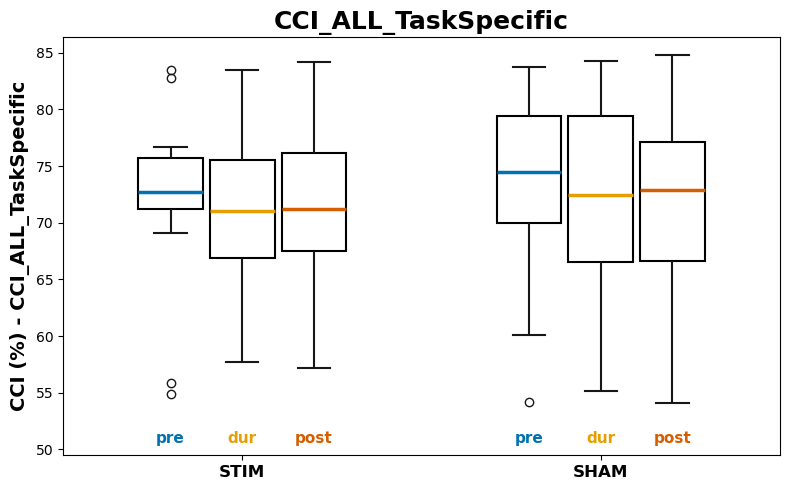

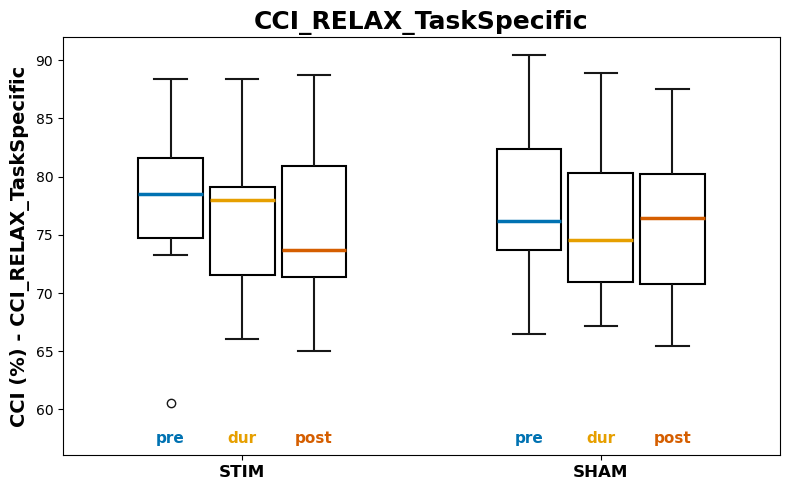

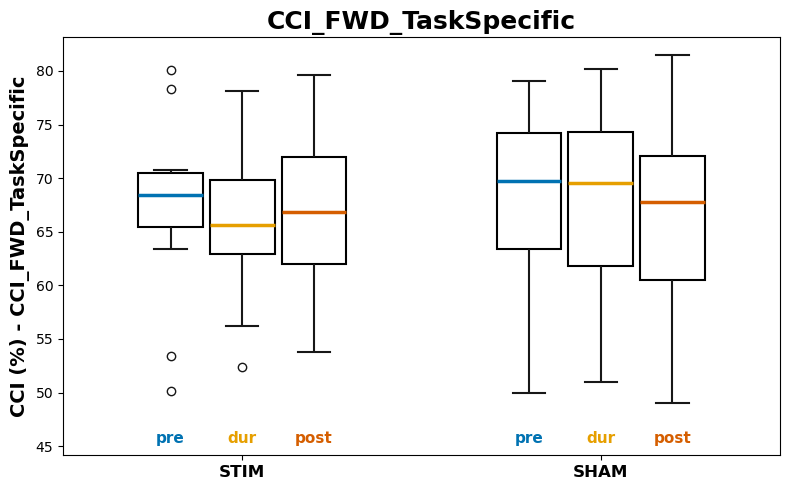

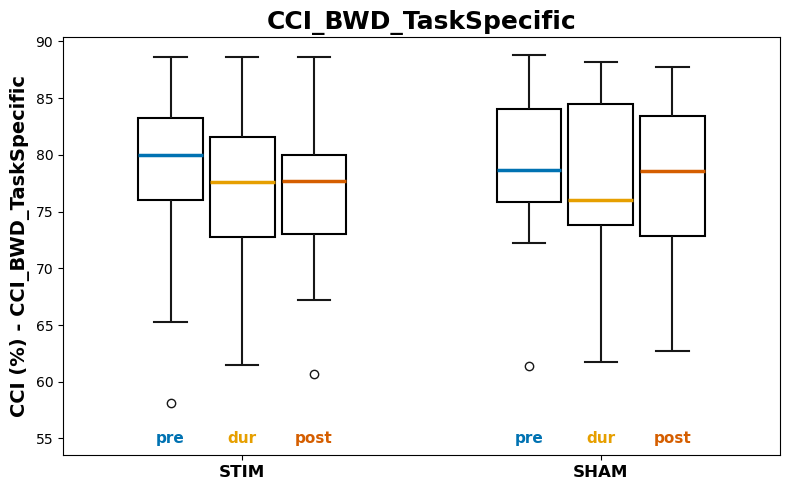


--- NORMALITY TEST ---
                Metric  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
  CCI_ALL_TaskSpecific        False          0.036        False          0.011
CCI_RELAX_TaskSpecific         True          0.105        False          0.034
  CCI_FWD_TaskSpecific         True          0.136         True          0.050
  CCI_BWD_TaskSpecific         True          0.097        False          0.028

--- rmANOVA RESULTS ---
                Metric  Time (F, p)  Stim (F, p) Interaction (F, p)
  CCI_ALL_TaskSpecific 2.208, 0.130 0.577, 0.461       1.028, 0.372
CCI_RELAX_TaskSpecific 4.326, 0.024 0.001, 0.972       0.162, 0.851
  CCI_FWD_TaskSpecific 1.889, 0.171 0.511, 0.487       2.008, 0.155
  CCI_BWD_TaskSpecific 2.347, 0.116 0.951, 0.347       0.019, 0.981

--- POST-HOC (STIM CONDITION, p < 0.1) ---
No post-hoc contrasts reached p < 0.1

SUB-ANÁLISIS CCI: Pure


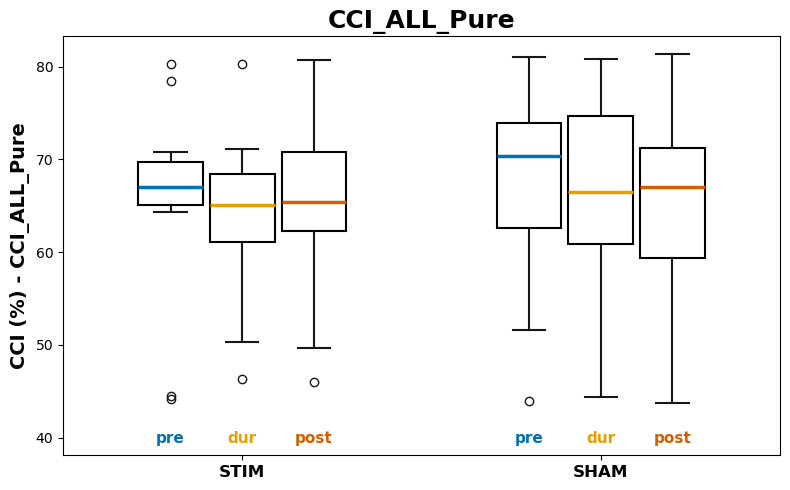

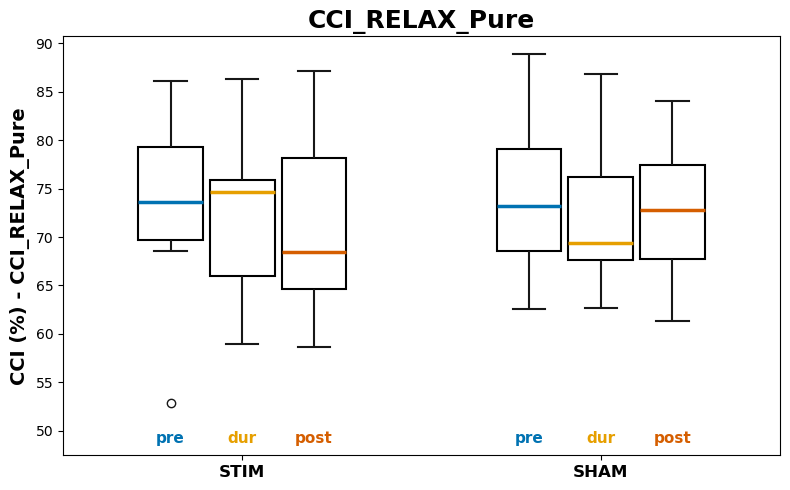

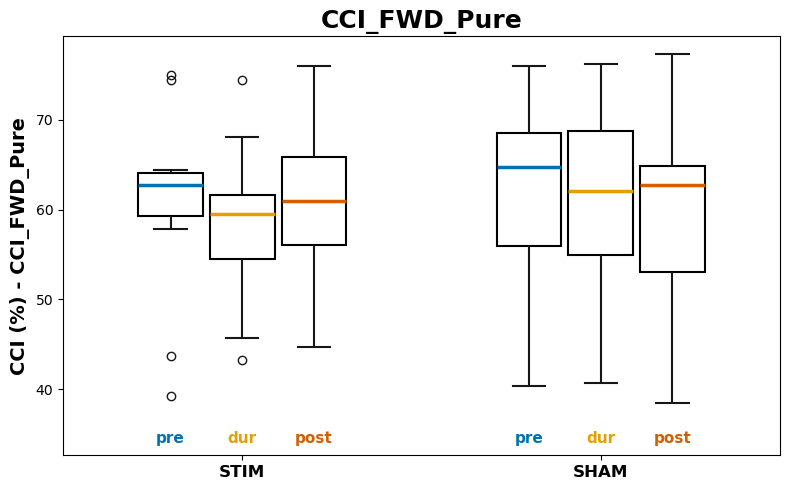

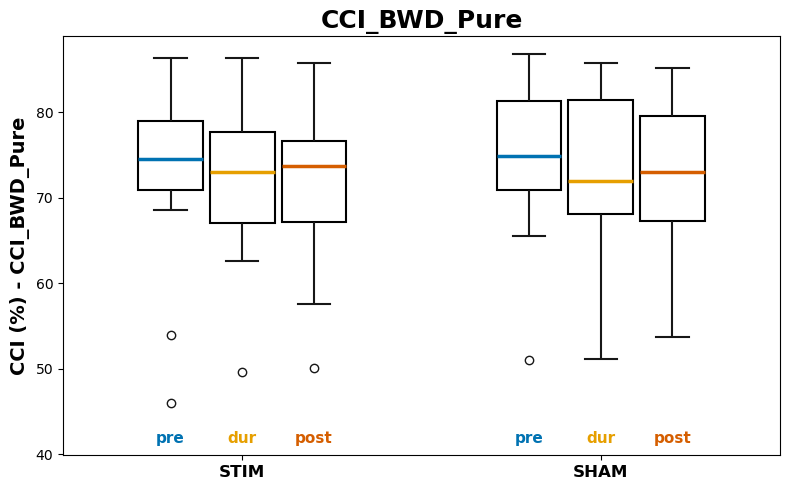


--- NORMALITY TEST ---
        Metric  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
  CCI_ALL_Pure        False          0.009        False          0.002
CCI_RELAX_Pure         True          0.162        False          0.038
  CCI_FWD_Pure        False          0.035        False          0.008
  CCI_BWD_Pure        False          0.028        False          0.005

--- rmANOVA RESULTS ---
        Metric  Time (F, p)  Stim (F, p) Interaction (F, p)
  CCI_ALL_Pure 2.348, 0.116 0.570, 0.464       1.418, 0.260
CCI_RELAX_Pure 2.942, 0.070 0.220, 0.647       0.109, 0.897
  CCI_FWD_Pure 2.396, 0.111 0.542, 0.475       2.840, 0.077
  CCI_BWD_Pure 1.906, 0.169 1.067, 0.320       0.101, 0.904

--- POST-HOC (STIM CONDITION, p < 0.1) ---
No post-hoc contrasts reached p < 0.1

SUB-ANÁLISIS CCI: Diag


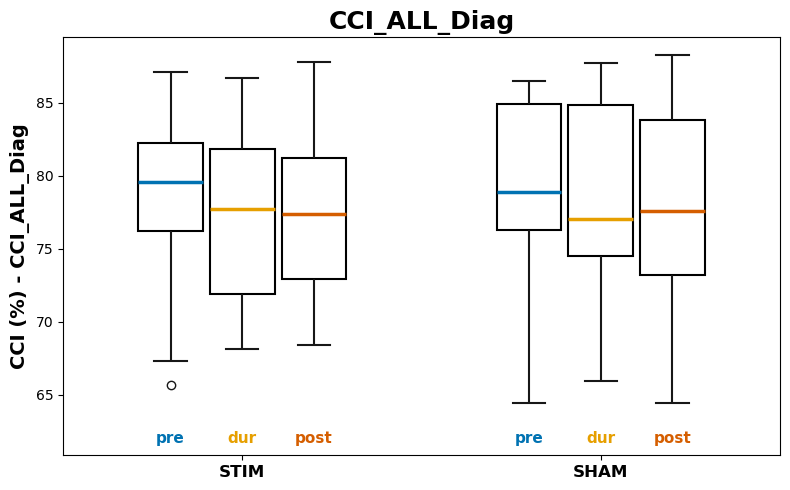

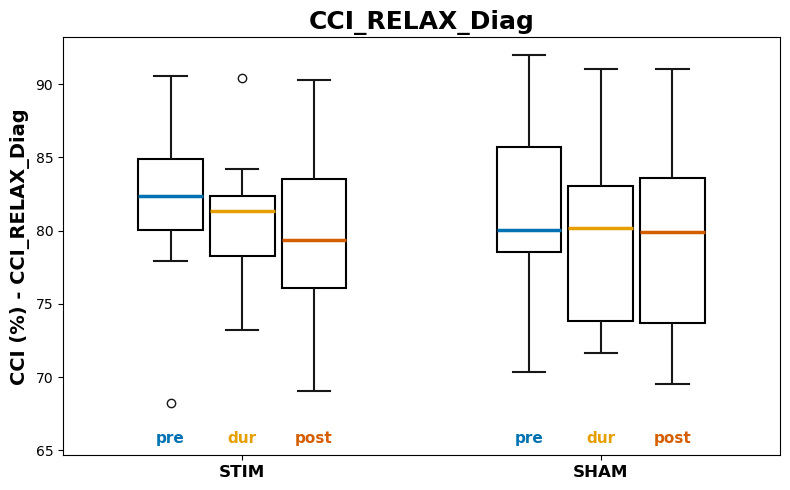

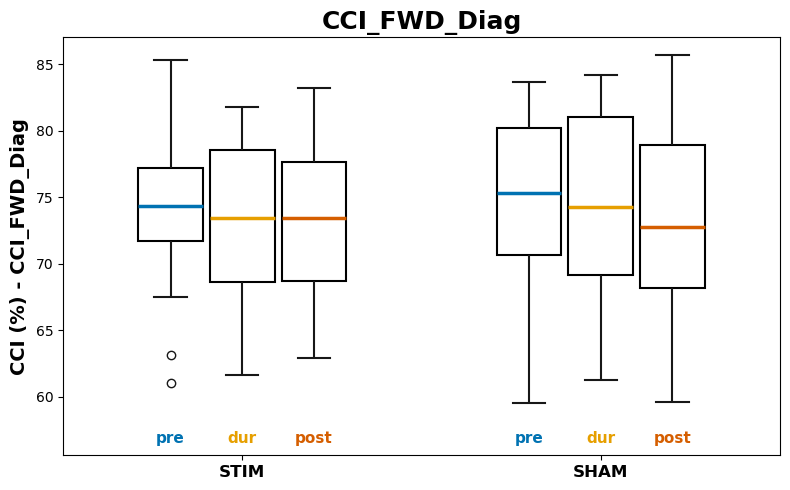

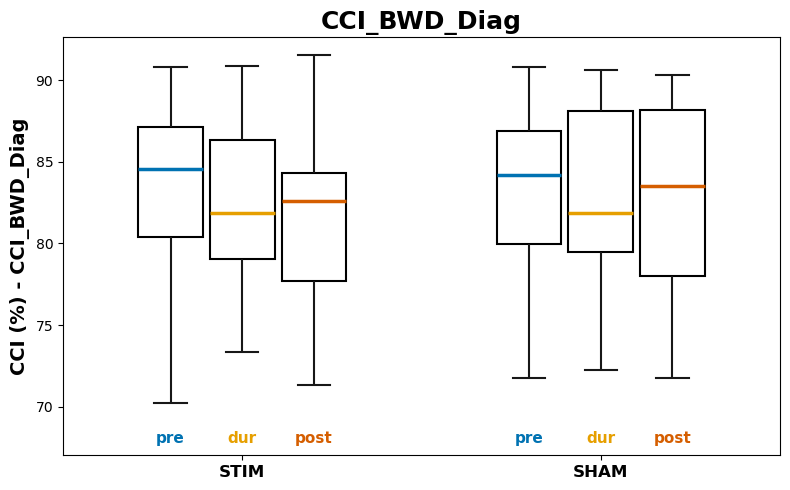


--- NORMALITY TEST ---
        Metric  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
  CCI_ALL_Diag         True          0.252         True          0.166
CCI_RELAX_Diag         True          0.118        False          0.050
  CCI_FWD_Diag         True          0.335         True          0.198
  CCI_BWD_Diag         True          0.292         True          0.246

--- rmANOVA RESULTS ---
        Metric  Time (F, p)  Stim (F, p) Interaction (F, p)
  CCI_ALL_Diag 1.385, 0.268 0.496, 0.494       0.566, 0.575
CCI_RELAX_Diag 5.398, 0.011 0.224, 0.644       0.265, 0.769
  CCI_FWD_Diag 0.768, 0.474 0.398, 0.539       0.550, 0.584
  CCI_BWD_Diag 2.133, 0.139 0.593, 0.455       0.701, 0.505

--- POST-HOC (STIM CONDITION, p < 0.1) ---
No post-hoc contrasts reached p < 0.1

SUB-ANÁLISIS CCI: FlexExt


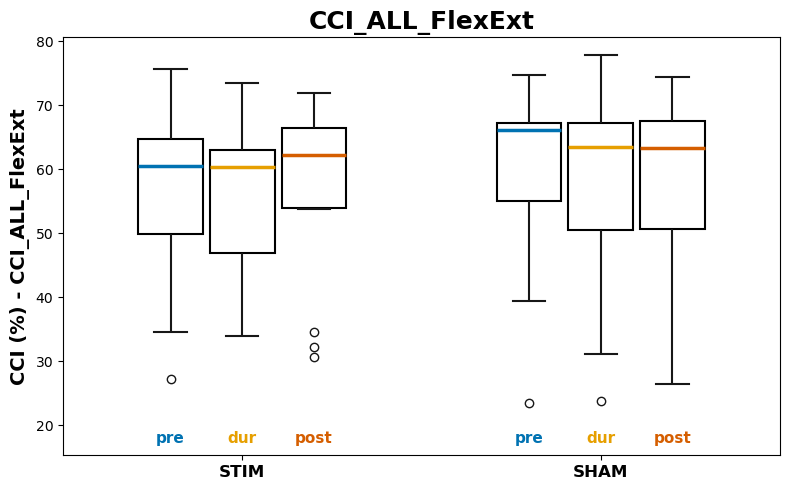

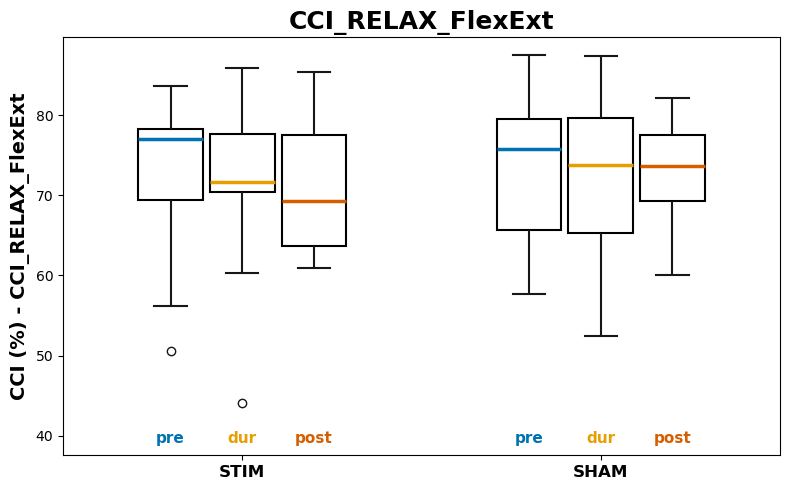

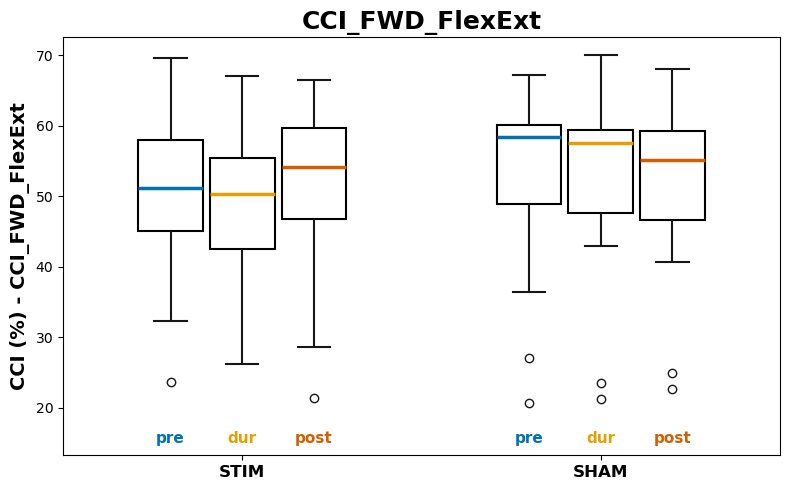

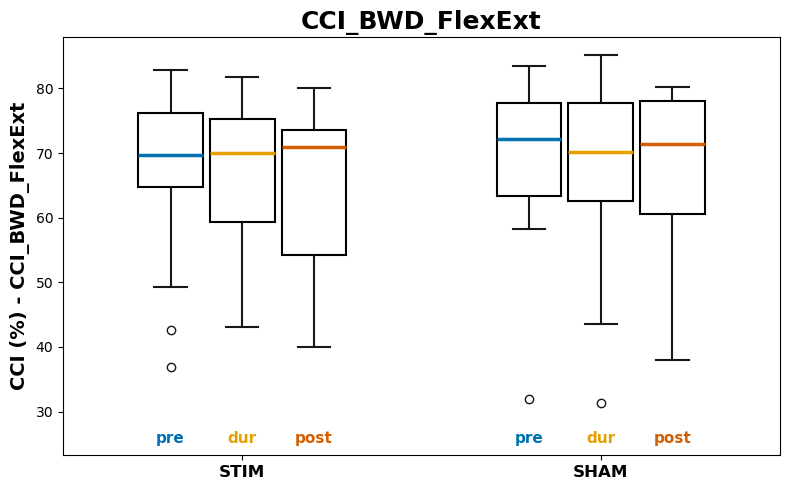


--- NORMALITY TEST ---
           Metric  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
  CCI_ALL_FlexExt        False          0.006        False          0.001
CCI_RELAX_FlexExt        False          0.040        False          0.011
  CCI_FWD_FlexExt        False          0.003        False          0.001
  CCI_BWD_FlexExt        False          0.019        False          0.001

--- rmANOVA RESULTS ---
           Metric  Time (F, p)  Stim (F, p) Interaction (F, p)
  CCI_ALL_FlexExt 0.673, 0.519 0.311, 0.587       0.590, 0.561
CCI_RELAX_FlexExt 0.337, 0.717 0.134, 0.720       0.004, 0.996
  CCI_FWD_FlexExt 0.522, 0.600 0.438, 0.520       1.880, 0.173
  CCI_BWD_FlexExt 0.857, 0.436 0.338, 0.571       0.236, 0.792

--- POST-HOC (STIM CONDITION, p < 0.1) ---
No post-hoc contrasts reached p < 0.1

SUB-ANÁLISIS CCI: RadUln


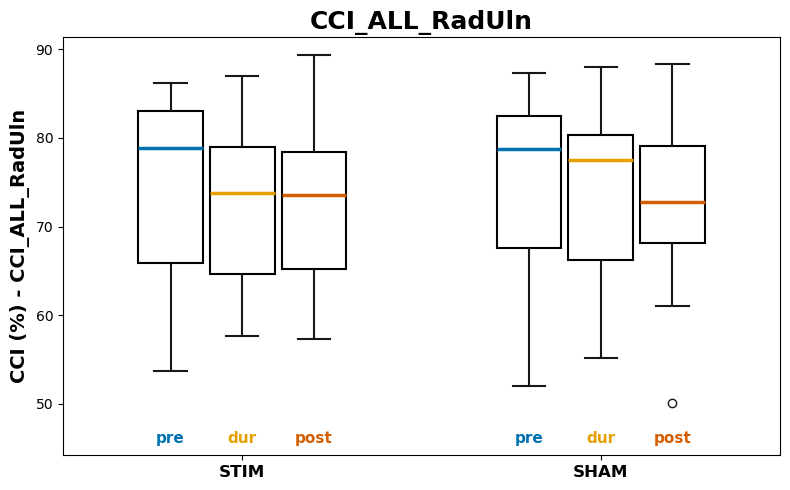

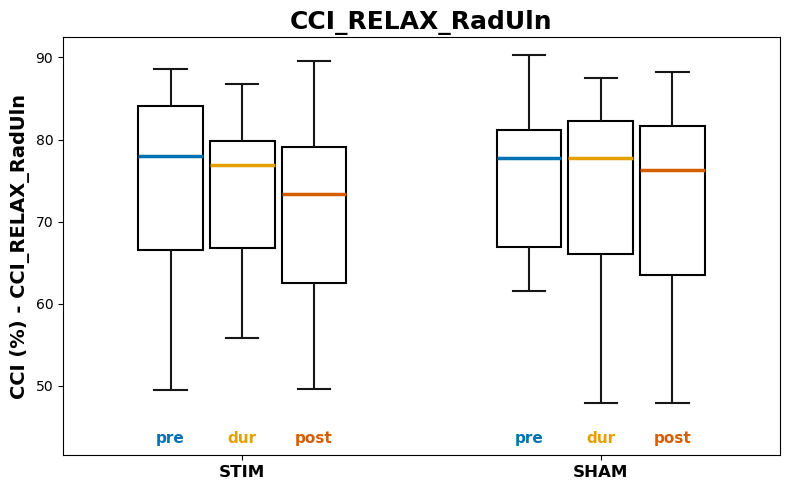

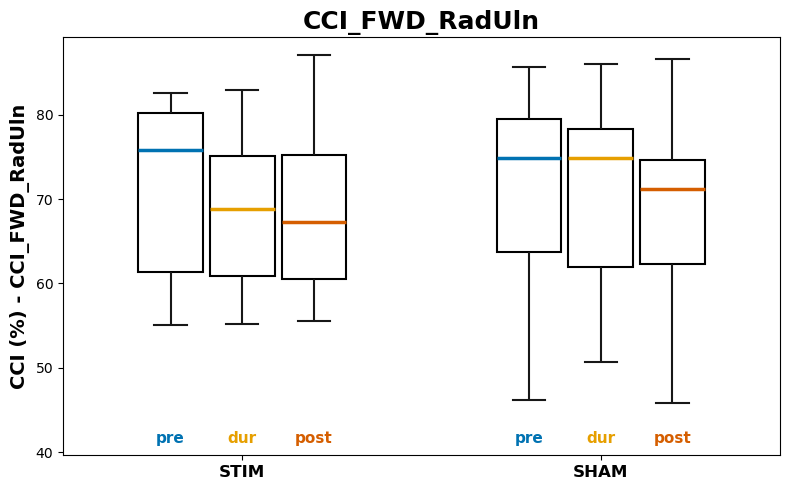

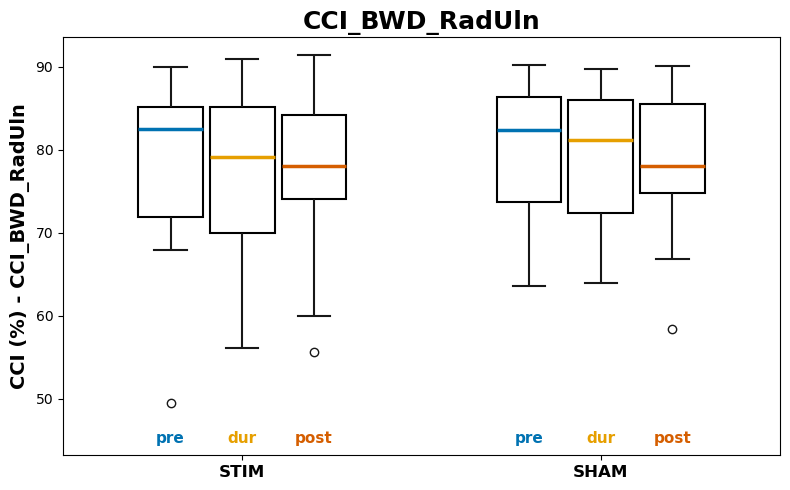


--- NORMALITY TEST ---
          Metric  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
  CCI_ALL_RadUln         True          0.087        False          0.049
CCI_RELAX_RadUln         True          0.135         True          0.059
  CCI_FWD_RadUln        False          0.017        False          0.012
  CCI_BWD_RadUln        False          0.035        False          0.006

--- rmANOVA RESULTS ---
          Metric  Time (F, p)  Stim (F, p) Interaction (F, p)
  CCI_ALL_RadUln 3.646, 0.040 0.177, 0.681       0.731, 0.491
CCI_RELAX_RadUln 3.594, 0.042 0.066, 0.802       0.273, 0.763
  CCI_FWD_RadUln 3.178, 0.058 0.040, 0.844       0.856, 0.437
  CCI_BWD_RadUln 3.296, 0.053 1.481, 0.245       0.399, 0.675

--- POST-HOC (STIM CONDITION, p < 0.1) ---
No post-hoc contrasts reached p < 0.1


In [22]:
import pandas as pd
import pingouin as pg
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

def graficar_boxplot(df, metrica, titulo, ylabel):
    niveles_tiempo = [t for t in ['PRE', 'DURING', 'POST'] if t in df['Time'].unique()]
    n_t = len(niveles_tiempo)
    
    fig = plt.figure(figsize=(8 if n_t == 3 else 6, 5 if n_t == 3 else 4))
    
    ax = sns.boxplot(
        data=df, x='Stimulation', y=metrica, hue='Time',
        order=['STIM', 'SHAM'], hue_order=niveles_tiempo,
        color='white', width=0.6 if n_t == 3 else 0.5, gap=0.1 if n_t == 3 else 0.15,
        linewidth=1.5, fliersize=6, medianprops=dict(linewidth=2.5)
    )
    
    for patch in ax.patches:
        patch.set_edgecolor('black')
        patch.set_facecolor('white')

    lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
    medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
    
    if n_t == 3:
        colores_estandar = ['#0072B2', '#E69F00', '#D55E00', '#0072B2', '#E69F00', '#D55E00']
        etiquetas = ['pre', 'dur', 'post', 'pre', 'dur', 'post']
    else:
        colores_estandar = ['#0072B2', '#D55E00', '#0072B2', '#D55E00']
        etiquetas = ['pre', 'post', 'pre', 'post']
        
    for mediana, color in zip(medianas_ordenadas, colores_estandar):
        mediana.set_color(color)

    plt.title(titulo, fontsize=18, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.xlabel('')
    plt.xticks(fontsize=12, fontweight='bold')
    
    if ax.legend_:
        ax.legend_.remove()
        
    y_min, y_max = df[metrica].min(), df[metrica].max()
    rango = (y_max - y_min) if (y_max != y_min) else 1.0
    offset_y = rango * 0.08
    
    cajas = ax.patches[:(2 * n_t)]
    cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
    posiciones_x = [p.get_path().get_extents().bounds[0] + (p.get_path().get_extents().bounds[2] / 2) for p in cajas_ordenadas]
    
    for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
        ax.text(x, y_min - offset_y, etiqueta, ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)
        
    plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
    plt.tight_layout()
    
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)
    fig.savefig(os.path.join(output_dir, f"{metrica}.png"), dpi=600, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def run_statistical_pipeline(csv_filepath, subtipos_analisis, usar_log=False, plot_validation=False):
    print("=" * 90)
    print(f"CARGANDO DATOS DESDE: {csv_filepath} | Bloque: Muscle Co-Contraction Index (CCI Bipolar)")
    print("=" * 90)
    
    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: Archivo '{csv_filepath}' no encontrado.")
        return
        
    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str)
    df['Time'] = df['Time'].astype(str)
    
    sujetos_excluidos_manual = ['1', '2', '10']
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]
    
    n_bloques_esperados = len(df['Time'].unique()) * 2
    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == n_bloques_esperados].index.tolist()
    df = df[df['Subject'].isin(sujetos_completos)].copy()
    
    print(f"Sujetos analizados con Cross-Over completo (N = {len(sujetos_completos)}, {n_bloques_esperados} bloques): {sorted(sujetos_completos, key=int)}")
    
    df['Condicion_Cruzada'] = df['Stimulation'] + "_" + df['Time']
    
    for subtipo in subtipos_analisis:
        print("\n" + "=" * 90)
        print(f"SUB-ANÁLISIS CCI: {subtipo}")
        print("=" * 90)
        
        metricas = [f"CCI_{fase}_{subtipo}" for fase in ['ALL', 'RELAX', 'FWD', 'BWD']]
        tabla_normalidad, tabla_anova, tabla_posthoc = [], [], []
        
        for metrica in metricas:
            if metrica not in df.columns:
                continue
                
            try:
                col_log = f"log_{metrica}"
                df[col_log] = np.log10(np.clip(df[metrica], a_min=1e-6, a_max=None))
                col_analisis = col_log if usar_log else metrica
                ylabel_plot = f"Log10 CCI (%) - {metrica}" if usar_log else f"CCI (%) - {metrica}"
                
                if plot_validation:
                    graficar_boxplot(df, col_analisis, metrica, ylabel_plot)
                
                pvals_raw = pg.normality(data=df, dv=metrica, group='Condicion_Cruzada')['pval'].values
                pvals_log = pg.normality(data=df, dv=col_log, group='Condicion_Cruzada')['pval'].values
                
                tabla_normalidad.append({
                    'Metric': metrica,
                    'Raw Normal?': all(p > 0.05 for p in pvals_raw),
                    'Raw Min p-val': round(min(pvals_raw), 3),
                    'Log Normal?': all(p > 0.05 for p in pvals_log),
                    'Log Min p-val': round(min(pvals_log), 3)
                })
                
                anova = pg.rm_anova(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', detailed=True)
                ef_time = anova[anova['Source'] == 'Time']
                ef_stim = anova[anova['Source'] == 'Stimulation']
                ef_int  = anova[anova['Source'] == 'Stimulation * Time']
                
                tabla_anova.append({
                    'Metric': metrica,
                    'Time (F, p)': f"{ef_time['F'].values[0]:.3f}, {ef_time['p-unc'].values[0]:.3f}",
                    'Stim (F, p)': f"{ef_stim['F'].values[0]:.3f}, {ef_stim['p-unc'].values[0]:.3f}",
                    'Interaction (F, p)': f"{ef_int['F'].values[0]:.3f}, {ef_int['p-unc'].values[0]:.3f}"
                })
                
                ph = pg.pairwise_tests(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', padjust='bonf', parametric=True)
                ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]
                
                for _, row in ph_stim.iterrows():
                    if row['p-corr'] < 0.1:
                        tabla_posthoc.append({
                            'Metric': metrica,
                            'Comparison': f"{row['A']} vs {row['B']} (STIM)",
                            'p-corr': round(row['p-corr'], 3),
                            'Hedges g': round(row['hedges'], 3)
                        })
            except Exception as e:
                print(f"  [!] Error procesando {metrica}: {e}")

        print("\n--- NORMALITY TEST ---")
        print(pd.DataFrame(tabla_normalidad).to_string(index=False))
        print("\n--- rmANOVA RESULTS ---")
        print(pd.DataFrame(tabla_anova).to_string(index=False))
        print("\n--- POST-HOC (STIM CONDITION, p < 0.1) ---")
        if tabla_posthoc:
            print(pd.DataFrame(tabla_posthoc).to_string(index=False))
        else:
            print("No post-hoc contrasts reached p < 0.1")

if __name__ == '__main__':
    ARCHIVO_CSV = "CCI_RM_ANOVA.csv"
    subtipos = ['TaskSpecific', 'Pure', 'Diag', 'FlexExt', 'RadUln']
    generate_validation = True
    
    run_statistical_pipeline(ARCHIVO_CSV, subtipos, usar_log=False, plot_validation=generate_validation)

## 2.4) CMC

In [23]:
import mne
import numpy as np
import pandas as pd
import os
import glob
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, welch, csd, resample
import gc

def preparar_emg_bipolar_rectificado(emg_unipolar, sfreq_emg, sfreq_target, hp_hz=20.0):
    """
    1. Convierte los 8 canales EMG unipolares en 4 músculos bipolares:
       - Índice 0: M1_ECRL (Radial:    M1L - M1R)
       - Índice 1: M2_ECU  (Extensión: M2L - M2R)
       - Índice 2: M3_FCR  (Flexión:   M3L - M3R)
       - Índice 3: M4_PL   (Ulnar:     M4L - M4R)
    2. Filtra pasa-altas a 20 Hz y rectifica en onda completa (demodulación Beta)
       ANTES de cualquier remuestreo temporal.
    3. Normaliza cada músculo a varianza unitaria (SD = 1) en el bloque para 
       homologar impedancias al combinar ensayos.
    """
    bipolar = np.stack([
        emg_unipolar[:, 0, :] - emg_unipolar[:, 1, :],  # 0: M1_ECRL (Radial)
        emg_unipolar[:, 2, :] - emg_unipolar[:, 3, :],  # 1: M2_ECU  (Extension)
        emg_unipolar[:, 4, :] - emg_unipolar[:, 5, :],  # 2: M3_FCR  (Flexion)
        emg_unipolar[:, 6, :] - emg_unipolar[:, 7, :]   # 3: M4_PL   (Ulnar)
    ], axis=1)

    nyq = 0.5 * sfreq_emg
    b_hp, a_hp = butter(4, hp_hz / nyq, btype='high')
    emg_filt = filtfilt(b_hp, a_hp, bipolar, axis=-1)

    # Rectificación de onda completa (demodula el comando corticoespinal Beta)
    emg_rect = np.abs(emg_filt)
    emg_rect = emg_rect - np.mean(emg_rect, axis=-1, keepdims=True)

    # Si las frecuencias de muestreo difieren, remuestrear después de rectificar
    if int(sfreq_emg) != int(sfreq_target):
        n_samples_target = int(round(emg_rect.shape[-1] * (sfreq_target / sfreq_emg)))
        emg_rect = resample(emg_rect, n_samples_target, axis=-1)

    # Estandarizar por músculo (SD = 1) para evitar sesgos de amplitud entre músculos
    std_vals = np.std(emg_rect, axis=(0, 2), keepdims=True)
    std_vals[std_vals <= 1e-12] = 1.0
    return emg_rect / std_vals

def construir_emg_agonista_por_fase(emg_bipolar_rect, events):
    """
    Para cada ensayo (epoch), selecciona el músculo agonista principal según el evento
    y la dirección del movimiento (invirtiendo agonista entre FORWARD y BACKWARD):
      - M0: Radial (M1_ECRL) | M1: Extensor (M2_ECU) | M2: Flexor (M3_FCR) | M3: Ulnar (M4_PL)
    Retorna tres matrices (n_epochs, n_times): emg_relax, emg_fwd, emg_bwd
    """
    n_ep, _, n_t = emg_bipolar_rect.shape
    emg_relax = np.zeros((n_ep, n_t))
    emg_fwd   = np.zeros((n_ep, n_t))
    emg_bwd   = np.zeros((n_ep, n_t))

    for i in range(n_ep):
        ev = events[i]
        m_rad, m_ext, m_flex, m_uln = emg_bipolar_rect[i, 0], emg_bipolar_rect[i, 1], emg_bipolar_rect[i, 2], emg_bipolar_rect[i, 3]

        if ev == 1:    # Flexion: Ida = Flexor (M3), Regreso = Extensor (M2)
            ago_fwd, ago_bwd = m_flex, m_ext
        elif ev == 2:  # Extension: Ida = Extensor (M2), Regreso = Flexor (M3)
            ago_fwd, ago_bwd = m_ext, m_flex
        elif ev == 3:  # Radial D.: Ida = Radial (M1), Regreso = Ulnar (M4)
            ago_fwd, ago_bwd = m_rad, m_uln
        elif ev == 4:  # Ulnar D.: Ida = Ulnar (M4), Regreso = Radial (M1)
            ago_fwd, ago_bwd = m_uln, m_rad
        elif ev == 5:  # D1 (Flex+Rad): Ida = Flex+Rad, Regreso = Ext+Uln
            ago_fwd, ago_bwd = 0.5 * (m_flex + m_rad), 0.5 * (m_ext + m_uln)
        elif ev == 6:  # D2 (Ext+Rad): Ida = Ext+Rad, Regreso = Flex+Uln
            ago_fwd, ago_bwd = 0.5 * (m_ext + m_rad), 0.5 * (m_flex + m_uln)
        elif ev == 7:  # D3 (Ext+Uln): Ida = Ext+Uln, Regreso = Flex+Rad
            ago_fwd, ago_bwd = 0.5 * (m_ext + m_uln), 0.5 * (m_flex + m_rad)
        elif ev == 8:  # D4 (Flex+Uln): Ida = Flex+Uln, Regreso = Ext+Rad
            ago_fwd, ago_bwd = 0.5 * (m_flex + m_uln), 0.5 * (m_ext + m_rad)
        else:
            ago_fwd, ago_bwd = m_flex, m_ext

        emg_fwd[i]   = ago_fwd
        emg_bwd[i]   = ago_bwd
        # En RELAX (preparación isométrica en el centro) usamos el agonista que se prepara para actuar en FWD
        emg_relax[i] = ago_fwd

    return emg_relax, emg_fwd, emg_bwd

def compute_epoch_coherence(eeg_win, emg_win, sfreq, fmin=15.0, fmax=29.0):
    """
    Calcula la Coherencia Cortico-Muscular (Halliday et al., 1995) en la banda Beta (15-29 Hz)
    usando segmentos de Welch de 1.0 s con 50% de solapamiento.
    eeg_win: shape (n_epochs, n_channels, n_times_win)
    emg_win: shape (n_epochs, n_times_win)
    """
    nperseg = min(int(sfreq), eeg_win.shape[-1])
    noverlap = nperseg // 2

    freqs, Pyy = welch(emg_win, fs=sfreq, nperseg=nperseg, noverlap=noverlap, axis=-1)
    mask_f = (freqs >= fmin) & (freqs <= fmax)
    Pyy_mean = np.mean(Pyy[:, mask_f], axis=0)  # Promedio sobre épocas

    n_ch = eeg_win.shape[1]
    coh_beta_ch = np.zeros(n_ch)
    coh_spectra = np.zeros((n_ch, len(freqs)))

    for ch_idx in range(n_ch):
        eeg_ch = eeg_win[:, ch_idx, :]
        _, Pxx = welch(eeg_ch, fs=sfreq, nperseg=nperseg, noverlap=noverlap, axis=-1)
        _, Pxy = csd(eeg_ch, emg_win, fs=sfreq, nperseg=nperseg, noverlap=noverlap, axis=-1)

        # Magnitud cuadrada del espectro cruzado medio dividida por el producto de auto-espectros medios
        Pxx_all = np.mean(Pxx, axis=0)
        Pxy_all = np.mean(Pxy, axis=0)
        Pyy_all = np.mean(Pyy, axis=0)

        coh_full = (np.abs(Pxy_all) ** 2) / (Pxx_all * Pyy_all + 1e-18)
        coh_spectra[ch_idx, :] = coh_full
        coh_beta_ch[ch_idx] = np.mean(coh_full[mask_f])

    return coh_beta_ch, freqs, coh_spectra

# ==============================================================================
# 0. Función de Generación de Gráficas de Validación (Espectro CMC)
# ==============================================================================
def generate_validation_plots(freqs, coh_relax, coh_fwd, coh_bwd, ch_names, subject_id, condition, time_blk, output_dir, run_name=""):
    fig_dir = os.path.join(output_dir, "Validation_Plots_CMC")
    os.makedirs(fig_dir, exist_ok=True)

    ch_plot = ['C3', 'C1', 'C4']
    picks_idx = [ch_names.index(c) for c in ch_plot if c in ch_names]
    if not picks_idx:
        return

    mask_plot = (freqs >= 5.0) & (freqs <= 40.0)
    f_p = freqs[mask_plot]

    fig, axes = plt.subplots(1, len(picks_idx), figsize=(5 * len(picks_idx), 4.2))
    if len(picks_idx) == 1:
        axes = [axes]

    for ax, idx in zip(axes, picks_idx):
        ch_name = ch_names[idx]
        ax.plot(f_p, coh_relax[idx, mask_plot], label='Relax (3-5s)', color='#0072B2', lw=1.5)
        ax.plot(f_p, coh_fwd[idx, mask_plot],   label='Forward (5-7s)', color='#D55E00', lw=2.0)
        ax.plot(f_p, coh_bwd[idx, mask_plot],   label='Backward (7.5-9.5s)', color='#009E73', lw=2.0)
        ax.axvspan(15, 29, color='pink', alpha=0.25, label='Beta (15-29 Hz)')
        ax.set_title(f"CMC - {ch_name} vs Agonist EMG\n({condition} - {time_blk})", fontweight='bold')
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Coherence Cxy(f)")
        ax.grid(True, alpha=0.3)
        if idx == picks_idx[0]:
            ax.legend(loc='upper right')

    plt.tight_layout()
    tag = run_name.replace('_eeg-epo.fif', '') if run_name else f"sub-{subject_id}_{condition}_{time_blk}"
    fig.savefig(os.path.join(fig_dir, f"CMC_{tag}.png"), dpi=300)
    plt.close(fig)

# ==============================================================================
# 1. Función de Extracción Matemática (CMC Global y Movimientos Puros)
# ==============================================================================
def extract_metrics(epochs_eeg, epochs_emg, subject_id="", condition="", time_blk="", base_out_dir="", filename="", plot_validation=False):
    sfreq_eeg = epochs_eeg.info['sfreq']
    sfreq_emg = epochs_emg.info['sfreq']
    times = epochs_eeg.times
    ch_names = epochs_eeg.ch_names

    n_min = min(len(epochs_eeg), len(epochs_emg))
    eeg_data = epochs_eeg.get_data()[:n_min]
    emg_unipolar = epochs_emg.get_data()[:n_min]
    events = epochs_eeg.events[:n_min, 2]

    # 1. Obtener los 4 canales EMG bipolares filtrados (20 Hz), rectificados y normalizados
    emg_bipolar_rect = preparar_emg_bipolar_rectificado(emg_unipolar, sfreq_emg, sfreq_eeg)

    # 2. Construir la matriz de agonista específico por ensayo y fase (con inversión FWD <-> BWD)
    emg_relax, emg_fwd, emg_bwd = construir_emg_agonista_por_fase(emg_bipolar_rect, events)

    mask_relax = (times >= 3.0) & (times <= 5.0)
    mask_fwd   = (times >= 5.0) & (times <= 7.0)
    mask_bwd   = (times >= 7.5) & (times <= 9.5)
    mask_all   = (times >= 5.0) & (times <= 9.5)

    # Para la ventana completa de movimiento (5.0-9.5s), concatenamos el agonista activo de cada subfase
    idx_split = np.argmin(np.abs(times - 7.25))
    emg_all_active = np.where(times[None, :] < 7.25, emg_fwd, emg_bwd)

    # A. Coherencia sobre todos los ensayos (Task-Specific: Eventos 1 a 8)
    cmc_all,   freqs, _        = compute_epoch_coherence(eeg_data[:, :, mask_all],   emg_all_active[:, mask_all], sfreq_eeg)
    cmc_relax, freqs, sp_relax = compute_epoch_coherence(eeg_data[:, :, mask_relax], emg_relax[:, mask_relax],    sfreq_eeg)
    cmc_fwd,   freqs, sp_fwd   = compute_epoch_coherence(eeg_data[:, :, mask_fwd],   emg_fwd[:, mask_fwd],        sfreq_eeg)
    cmc_bwd,   freqs, sp_bwd   = compute_epoch_coherence(eeg_data[:, :, mask_bwd],   emg_bwd[:, mask_bwd],        sfreq_eeg)

    if plot_validation:
        generate_validation_plots(freqs, sp_relax, sp_fwd, sp_bwd, ch_names, subject_id, condition, time_blk, base_out_dir, filename)

    # B. Coherencia solo sobre movimientos puros cardinales (Eventos 1 a 4: agonista único sin sinergia)
    mask_pure = np.isin(events, [1, 2, 3, 4])
    if np.sum(mask_pure) >= 4:
        cmc_fwd_pure, _, _ = compute_epoch_coherence(eeg_data[mask_pure][:, :, mask_fwd], emg_fwd[mask_pure][:, mask_fwd], sfreq_eeg)
        cmc_bwd_pure, _, _ = compute_epoch_coherence(eeg_data[mask_pure][:, :, mask_bwd], emg_bwd[mask_pure][:, mask_bwd], sfreq_eeg)
    else:
        cmc_fwd_pure = np.full(len(ch_names), np.nan)
        cmc_bwd_pure = np.full(len(ch_names), np.nan)

    resultados = {}
    for i, ch in enumerate(ch_names):
        resultados[f"CMC_ALL_{ch}"]      = cmc_all[i]
        resultados[f"CMC_RELAX_{ch}"]    = cmc_relax[i]
        resultados[f"CMC_FWD_{ch}"]      = cmc_fwd[i]
        resultados[f"CMC_BWD_{ch}"]      = cmc_bwd[i]
        resultados[f"CMC_FWD_PURE_{ch}"] = cmc_fwd_pure[i]
        resultados[f"CMC_BWD_PURE_{ch}"] = cmc_bwd_pure[i]

    return pd.DataFrame([resultados])

# ==============================================================================
# 2. Pipeline Principal (Con Emparejamiento EEG-EMG y Limpieza de RAM)
# ==============================================================================
def process_metric(preprocessed_folder, output_csv, sujetos_a_procesar=None, plot_validation=False):
    print(f"Buscando archivos EEG y EMG emparejados en: {preprocessed_folder}")

    search_pattern = os.path.join(preprocessed_folder, "*_eeg-epo.fif")
    archivos_eeg = [f for f in glob.glob(search_pattern) if 'blk-basal' not in os.path.basename(f).lower()]

    if not archivos_eeg:
        print("No se encontraron archivos *_eeg-epo.fif válidos. Verifica la ruta.")
        return

    print(f"Se encontraron {len(archivos_eeg)} sesiones. Iniciando cálculo de CMC Bipolar...\n")
    lista_resultados = []
    base_out_dir = os.path.dirname(os.path.abspath(output_csv)) or os.getcwd()

    for filepath_eeg in archivos_eeg:
        filename = os.path.basename(filepath_eeg)
        filepath_emg = filepath_eeg.replace("_eeg-epo.fif", "_emg-epo.fif")

        if not os.path.exists(filepath_emg):
            print(f"  [!] Archivo EMG no encontrado para {filename}, omitiendo...")
            continue

        epochs_eeg, epochs_emg = None, None
        try:
            partes = filename.split('_')
            subject_id = partes[0].split('-')[1]

            if sujetos_a_procesar is not None and subject_id not in sujetos_a_procesar:
                continue

            condition = partes[1].split('-')[1].upper()
            if 'pre' in filename.lower(): time_blk = 'PRE'
            elif 'during' in filename.lower(): time_blk = 'DURING'
            elif 'post' in filename.lower(): time_blk = 'POST'
            else: continue

            print(f"Procesando CMC: Sujeto {subject_id} | {condition} | {time_blk}")
            epochs_eeg = mne.read_epochs(filepath_eeg, preload=True, verbose=False)
            epochs_emg = mne.read_epochs(filepath_emg, preload=True, verbose=False)

            df_resumen = extract_metrics(
                epochs_eeg, epochs_emg,
                subject_id=subject_id, condition=condition, time_blk=time_blk,
                base_out_dir=base_out_dir, filename=filename, plot_validation=plot_validation
            )
            df_resumen['Subject'] = subject_id
            df_resumen['Stimulation'] = condition
            df_resumen['Time'] = time_blk

            lista_resultados.append(df_resumen)

        except Exception as e:
            print(f"  [!] Error procesando CMC en {filename}: {e}")
        finally:
            if epochs_eeg is not None: del epochs_eeg
            if epochs_emg is not None: del epochs_emg
            plt.close('all')
            gc.collect()

    print("\nConsolidando tabla maestra de CMC...")
    if lista_resultados:
        df_todos = pd.concat(lista_resultados, ignore_index=True)
        df_maestro = df_todos.groupby(['Subject', 'Stimulation', 'Time']).mean(numeric_only=True).reset_index()

        cols_metadatos = ['Subject', 'Stimulation', 'Time']
        cols_metricas = [c for c in df_maestro.columns if c not in cols_metadatos]
        df_maestro = df_maestro[cols_metadatos + cols_metricas]

        df_maestro.to_csv(output_csv, index=False)
        print(f"\n¡Éxito! Matriz de Coherencia Cortico-Muscular exportada a: {output_csv}")
        print(df_maestro.head())
    else:
        print("\n[!] No se generaron resultados para exportar.")

if __name__ == '__main__':
    Preprocessed_Data_Folder = r"E:\Yoyi\Preprocessed Data"
    Archivo_Salida_CSV = "CMC_RM_ANOVA.csv"
    generate_validation = True

    process_metric(Preprocessed_Data_Folder, Archivo_Salida_CSV, plot_validation=generate_validation)

Buscando archivos EEG y EMG emparejados en: E:\Yoyi\Preprocessed Data
Se encontraron 102 sesiones. Iniciando cálculo de CMC Bipolar...

Procesando CMC: Sujeto 10 | SHAM | DURING
Procesando CMC: Sujeto 10 | SHAM | POST
Procesando CMC: Sujeto 10 | SHAM | PRE
Procesando CMC: Sujeto 10 | STIM | DURING
Procesando CMC: Sujeto 10 | STIM | POST
Procesando CMC: Sujeto 10 | STIM | PRE
Procesando CMC: Sujeto 11 | SHAM | DURING
Procesando CMC: Sujeto 11 | SHAM | POST
Procesando CMC: Sujeto 11 | SHAM | PRE
Procesando CMC: Sujeto 11 | STIM | DURING
Procesando CMC: Sujeto 11 | STIM | POST
Procesando CMC: Sujeto 11 | STIM | PRE
Procesando CMC: Sujeto 12 | SHAM | DURING
Procesando CMC: Sujeto 12 | SHAM | POST
Procesando CMC: Sujeto 12 | SHAM | PRE
Procesando CMC: Sujeto 12 | STIM | DURING
Procesando CMC: Sujeto 12 | STIM | POST
Procesando CMC: Sujeto 12 | STIM | PRE
Procesando CMC: Sujeto 13 | SHAM | DURING
Procesando CMC: Sujeto 13 | SHAM | POST
Procesando CMC: Sujeto 13 | SHAM | PRE
Procesando CMC: S

### Statistical Analysis

In [24]:
import pandas as pd
import pingouin as pg
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

def graficar_boxplot(df, metrica, titulo, ylabel):
    fig = plt.figure(figsize=(8, 5))
    ax = sns.boxplot(
        data=df, x='Stimulation', y=metrica, hue='Time',
        order=['STIM', 'SHAM'], hue_order=['PRE', 'DURING', 'POST'],
        color='white', width=0.6, gap=0.1, linewidth=1.5,
        fliersize=6, medianprops=dict(linewidth=2.5)
    )
    for patch in ax.patches:
        patch.set_edgecolor('black')
        patch.set_facecolor('white')

    lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
    medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
    colores_estandar = ['#0072B2', '#E69F00', '#D55E00', '#0072B2', '#E69F00', '#D55E00']
    for mediana, color in zip(medianas_ordenadas, colores_estandar):
        mediana.set_color(color)

    plt.title(titulo, fontsize=18, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.xlabel('')
    plt.xticks(fontsize=12, fontweight='bold')
    if ax.legend_:
        ax.legend_.remove()

    y_min, y_max = df[metrica].min(), df[metrica].max()
    rango = (y_max - y_min) if (y_max != y_min) else 1.0
    offset_y = rango * 0.08

    cajas = ax.patches[:6]
    cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
    posiciones_x = [p.get_path().get_extents().bounds[0] + (p.get_path().get_extents().bounds[2] / 2) for p in cajas_ordenadas]
    etiquetas = ['pre', 'dur', 'post', 'pre', 'dur', 'post']

    for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
        ax.text(x, y_min - offset_y, etiqueta, ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)

    plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
    plt.tight_layout()

    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)
    fig.savefig(os.path.join(output_dir, f"{metrica}.png"), dpi=600, bbox_inches='tight')
    plt.close(fig)

def run_statistical_pipeline(csv_filepath, canales, tipo_metrica="CMC_FWD", usar_log=True, plot_validation=False):
    print("=" * 90)
    print(f"CARGANDO DATOS DESDE: {csv_filepath} | Métrica: {tipo_metrica}")
    print("=" * 90)

    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: Archivo '{csv_filepath}' no encontrado.")
        return

    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str)
    df['Time'] = df['Time'].astype(str)

    sujetos_excluidos_manual = ['1', '2', '10']
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]

    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == 6].index.tolist()
    df = df[df['Subject'].isin(sujetos_completos)].copy()

    print(f"Sujetos analizados con 6 bloques completos (N = {len(sujetos_completos)}): {sorted(sujetos_completos, key=int)}")

    df['Condicion_Cruzada'] = df['Stimulation'] + "_" + df['Time']
    tabla_normalidad, tabla_anova, tabla_posthoc = [], [], []

    for canal in canales:
        metrica_col = f"{tipo_metrica}_{canal}"
        if metrica_col not in df.columns:
            continue

        try:
            col_log = f"log_{metrica_col}"
            df[col_log] = np.log10(np.clip(df[metrica_col], a_min=1e-8, a_max=None))
            col_analisis = col_log if usar_log else metrica_col
            ylabel_plot = f"Log10 {tipo_metrica} - {canal}" if usar_log else f"{tipo_metrica} - {canal}"

            if plot_validation:
                graficar_boxplot(df, col_analisis, f"{tipo_metrica} Beta - {canal}", ylabel_plot)

            pvals_raw = pg.normality(data=df, dv=metrica_col, group='Condicion_Cruzada')['pval'].values
            pvals_log = pg.normality(data=df, dv=col_log, group='Condicion_Cruzada')['pval'].values

            tabla_normalidad.append({
                'Channel': canal,
                'Raw Normal?': all(p > 0.05 for p in pvals_raw),
                'Raw Min p-val': round(min(pvals_raw), 3),
                'Log Normal?': all(p > 0.05 for p in pvals_log),
                'Log Min p-val': round(min(pvals_log), 3)
            })

            anova = pg.rm_anova(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', detailed=True)
            ef_time = anova[anova['Source'] == 'Time']
            ef_stim = anova[anova['Source'] == 'Stimulation']
            ef_int  = anova[anova['Source'] == 'Stimulation * Time']

            tabla_anova.append({
                'Channel': canal,
                'Time (F, p)': f"{ef_time['F'].values[0]:.3f}, {ef_time['p-unc'].values[0]:.3f}",
                'Stim (F, p)': f"{ef_stim['F'].values[0]:.3f}, {ef_stim['p-unc'].values[0]:.3f}",
                'Interaction (F, p)': f"{ef_int['F'].values[0]:.3f}, {ef_int['p-unc'].values[0]:.3f}"
            })

            ph = pg.pairwise_tests(data=df, dv=col_analisis, within=['Stimulation', 'Time'], subject='Subject', padjust='bonf', parametric=True)
            ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]

            for _, row in ph_stim.iterrows():
                if row['p-corr'] < 0.1:
                    tabla_posthoc.append({
                        'Channel': canal,
                        'Comparison': f"{row['A']} vs {row['B']} (STIM)",
                        'p-corr': round(row['p-corr'], 3),
                        'Hedges g': round(row['hedges'], 3)
                    })

        except Exception as e:
            print(f"  [!] Error procesando el canal {canal}: {e}")

    print("\n--- NORMALITY TEST ---")
    print(pd.DataFrame(tabla_normalidad).to_string(index=False))
    print("\n--- rmANOVA RESULTS ---")
    print(pd.DataFrame(tabla_anova).to_string(index=False))
    print("\n--- POST-HOC (STIM CONDITION, p < 0.1) ---")
    if tabla_posthoc:
        print(pd.DataFrame(tabla_posthoc).to_string(index=False))
    else:
        print("No post-hoc contrasts reached p < 0.1")

if __name__ == '__main__':
    ARCHIVO_CSV = "CMC_RM_ANOVA.csv"
    canales_eeg = ['C3', 'C1', 'Cz', 'C2', 'C4', 'CP1', 'CP2', 'Pz']
    generate_validation = True

    for metrica_cmc in ["CMC_ALL", "CMC_RELAX", "CMC_FWD", "CMC_BWD", "CMC_FWD_PURE", "CMC_BWD_PURE"]:
        run_statistical_pipeline(ARCHIVO_CSV, canales_eeg, tipo_metrica=metrica_cmc, usar_log=True, plot_validation=generate_validation)

CARGANDO DATOS DESDE: CMC_RM_ANOVA.csv | Métrica: CMC_ALL
Sujetos analizados con 6 bloques completos (N = 14): ['5', '6', '7', '8', '9', '11', '12', '13', '16', '17', '18', '19', '20', '21']

--- NORMALITY TEST ---
Channel  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
     C3        False          0.000         True          0.208
     C1        False          0.012         True          0.522
     Cz        False          0.000         True          0.050
     C2        False          0.000        False          0.017
     C4        False          0.000        False          0.007
    CP1        False          0.000        False          0.001
    CP2        False          0.000        False          0.004
     Pz        False          0.000        False          0.000

--- rmANOVA RESULTS ---
Channel   Time (F, p)  Stim (F, p) Interaction (F, p)
     C3  1.478, 0.247 1.275, 0.279       0.202, 0.818
     C1 12.118, 0.000 2.211, 0.161       0.167, 0.847
     Cz  0.400, 0.674 